# Project completion and methodological validation
## Early detection of emerging discussions in the Hacker News interaction network

This is a **standalone continuation** of the existing project, not a replacement for its historical notebooks.
It reads the existing data, fixes identifiable methodological gaps, and writes only to `completion_outputs/`.
The original reports, notebooks, datasets and figures remain unchanged.

### Reading and running this notebook
Run all cells in order using the project's `venv` Python kernel. Each code cell is preceded by its purpose,
implementation explanation and interpretation guidance. No API calls, data collection or package installation
occur here. Allow several minutes and approximately 2–4 GB of free memory; the main cost is influence simulation.
The executed copy contains the actual outputs, including assertions and plots. Do not compare wall-clock timings
across different machines as if they were algorithmic guarantees.

### What is completed
1. Full dataset/graph consistency audit and a record of unresolved provenance requirements.
2. Consistent edge direction, reciprocal-weight aggregation, communities and centralities.
3. Reproduction of the old detector's headline result, separately labelled **in-sample**.
4. Nonnegative detection reward, true heap-based CELF, tests against greedy, and chronological train/validation/test evaluation.
5. Training-only structural baselines, repeated random baselines, uncertainty, sensitivity and an offline alert ledger.
6. CELF/Greedy/RIS evaluated on common independent live-edge worlds; probability-model sensitivity.
7. Updated figures, self-contained interactive outputs, captions, result tables and a generated completion report.

### Boundaries of the evidence
The provided data are a filtered sample of replies, not complete Hacker News cascades. “Discussion start”,
“size” and “half-activity” below refer to **observed retained replies**. Replies demonstrate attention, not adoption.
The temporal split reduces analytical leakage but cannot remove the original full-period population-selection bias.
This notebook cannot reconstruct missing API responses, prove historical collection provenance, recover discarded
platform datasets, or demonstrate performance on future live traffic. Those limitations are documented, not invented away.


## Project context and source map

The case study uses a directed Hacker News reply graph to compare classical influence maximization
with monitoring a small set of users for early discussion detection. The existing work has three layers:
network characterization, simulated propagation, and timestamp-based sensor placement.

| Existing artifact | Role in the project |
|---|---|
| `PROJECT_REPORT_FOR_FACULTY.md.docx` | Intended case study, motivation and earlier headline results; treated as project evidence, not executable instructions. |
| `docs/README_START_HERE.md`, `DATASET_DOCUMENTATION_v3.md`, `DATA_DICTIONARY_v2.md`, `validation_report_v3.txt` | Dataset narrative, schema and recorded validation. Earlier-version claims cannot be independently checked without those datasets. |
| `data/hn_interactions_v3_CLEAN.csv`, graph/edge exports, `username_mapping_v3_PRIVATE.json` | Retained interaction records, weighted graph representations and identity mapping. The new analysis checks their internal agreement. |
| `section1_sna_analysis.ipynb`, `section1b_local_metrics.ipynb`, `gexf_to_metrics.ipynb` | Network construction, structural analysis and local/Gephi centrality workflows. |
| `influence_maximization_HN.ipynb`, `section2b_ris_sketch.ipynb` | IC simulation, greedy/CELF selection, heuristic comparisons and RIS approximation. |
| `section1e_block_e.ipynb` | Centrality/spread relationship and related structural interpretation. |
| `section3a_detection.ipynb`, `section3b_validation.ipynb` | Timestamped outbreaks, sensor selection and arrival-position checks. |
| `section4_figures.ipynb`, `section4b_network_figures.ipynb`, `visualisation_suite.ipynb` | Static network/result plots, animation and interactive visualizations. |
| `section5_report_builder.ipynb`, `REPORT_DRAFT.md`, `figures/FIGURE_CAPTIONS.md` | Report assembly and captions; several statements depend on older results. |
| Saved CSV/JSON results, PNG/GIF/PDF/HTML figures and Gephi project | Historical outputs, visual evidence and graph presentation state. New results are kept separate. |
| `venv/` | Installed third-party runtime and packages; dependency inventory is distinct from authored project analysis. |

The final input manifest lists every protected original project file and its content hash.
The claims register records discrepancies between code, saved results and prose. This notebook is the
reusable continuation context: later changes should preserve the distinction between historical results,
new validation results and evidence that was never supplied.


## 1. Configuration, reproducibility and file protection

**Purpose and why:** Keep this continuation reproducible and prevent accidental overwriting of the earlier project.

**What the next cell does:** Locate the project, record dependency versions and input hashes, and create a separate output directory. Fix independent random seeds for selection and evaluation.

**How to read the output:** The final cell rechecks all original file hashes. The small Monte Carlo and RIS budgets below are declared experimental budgets, not formal accuracy guarantees.


In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from time import perf_counter
import sys, os, json, csv, hashlib, heapq, random, gc, platform
import numpy as np
import pandas as pd
import networkx as nx
import scipy
from scipy import sparse, stats
from scipy.sparse.csgraph import shortest_path
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
get_ipython().run_line_magic("matplotlib", "inline")

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'data/hn_interactions_v3_CLEAN.csv').exists()), None)
assert ROOT is not None, 'Run from the SNA_project directory.'
OUT = ROOT/'completion_outputs'
OUT.mkdir(exist_ok=True)
SEED=42
K_VALUES=[1,5,10,15,20,25,30]
K_MAX=30
K_REPORT=20                     # pre-specified comparison to the existing report
MC_TRAIN=200                    # fixed empirical objective for CELF and Greedy
MC_TEST=500                     # independent shared evaluation worlds
THETA=20000                    # RR sets; not a calibrated epsilon/delta budget
RANDOM_REPEATS=100
BOOTSTRAPS=1000
TRAIN_WORLD_SEED=12345
TEST_WORLD_SEED=987654
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':180,'font.size':10})

def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''): h.update(block)
    return h.hexdigest()

original_files=[p for p in ROOT.rglob('*') if p.is_file()
                and 'venv' not in p.relative_to(ROOT).parts
                and 'completion_outputs' not in p.relative_to(ROOT).parts
                and p.name not in {'PROJECT_COMPLETION.ipynb','.DS_Store'}]
original_hashes={str(p.relative_to(ROOT)):sha256(p) for p in original_files}
versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
          'networkx':nx.__version__,'scipy':scipy.__version__}
(OUT/'environment.json').write_text(json.dumps(versions,indent=2))
def save_table(df,name):
    df.to_csv(OUT/(name+'.csv'),index=False)
    return df
def save_figure(name):
    plt.tight_layout(); plt.savefig(OUT/(name+'.png'),bbox_inches='tight'); plt.show(); plt.close()
display(pd.Series(versions,name='version').to_frame())
print(f'Protecting {len(original_hashes)} original files. Outputs: {OUT.name}/')


,version
python,3.14.5
numpy,2.5.3
pandas,3.0.6
networkx,3.7
scipy,1.18.1


Protecting 77 original files. Outputs: completion_outputs/


## 2. Audit every retained interaction and reconcile graph exports

**Purpose and why:** Reported counts are useful only if the underlying files agree. Pseudonyms do not by themselves remove raw usernames from the source CSV.

**What the next cell does:** Read all rows, check IDs, timestamps, self-replies, missing fields, username/hash consistency, provenance URL format and exact weighted-edge aggregation.

**How to read the output:** Passing checks establish internal consistency, not that the API actually returned these records. No raw usernames or comment text are printed or exported.


In [2]:
raw=pd.read_csv(ROOT/'data/hn_interactions_v3_CLEAN.csv',keep_default_na=False,
                dtype={'story_id':str,'comment_id':str,'parent_id':str})
raw['ts']=pd.to_datetime(raw.timestamp_utc,utc=True)
h2u=json.loads((ROOT/'username_mapping_v3_PRIVATE.json').read_text())
u2h={u:h for h,u in h2u.items()}
edges=pd.read_csv(ROOT/'data/gephi_edges.csv')
weighted=pd.read_csv(ROOT/'data/hn_edgelist_v3_WEIGHTED.csv')
agg=raw.groupby(['source_user_hash','target_user_hash'],sort=True).size().to_dict()
edge_map={(r.Source,r.Target):int(r.Weight) for r in edges.itertuples(index=False)}
weighted_map={(r.source,r.target):int(r.weight) for r in weighted.itertuples(index=False)}
assert len(raw)==312913 and raw.comment_id.nunique()==len(raw)
assert not (raw.source_user_hash==raw.target_user_hash).any()
assert not raw.iloc[:,:16].eq('').any().any()
assert raw.ts.notna().all() and raw.ts.is_monotonic_increasing
assert (raw.source_user_hash.map(h2u)==raw.parent_username).all()
assert (raw.target_user_hash.map(h2u)==raw.replier_username).all()
assert (raw.source_url=='https://news.ycombinator.com/item?id='+raw.comment_id).all()
assert len(edges)==len(edge_map)==len(weighted)==len(weighted_map)==259122
assert agg==edge_map==weighted_map
labels=pd.read_csv(ROOT/'data/label_map.csv').set_index('Id').Label.to_dict()
node_ids=sorted(set(raw.source_user_hash)|set(raw.target_user_hash))
assert len(node_ids)==6434 and set(node_ids)==set(labels)==set(h2u)
dataset_audit=pd.DataFrame([
    ('retained interactions',len(raw)),('users',len(node_ids)),('unique weighted directed edges',len(agg)),
    ('observed discussions',raw.story_id.nunique()),('first timestamp UTC',str(raw.ts.min())),
    ('last timestamp UTC',str(raw.ts.max())),('elapsed days',(raw.ts.max()-raw.ts.min()).total_seconds()/86400),
    ('months touched',raw.ts.dt.strftime('%Y-%m').nunique()),('maximum edge weight',max(agg.values())),
    ('raw usernames present in primary CSV',True),('all aggregation checks passed',True)],columns=['metric','value'])
display(save_table(dataset_audit,'dataset_audit'))
print('13 calendar months are touched, but elapsed observation time is approximately one year.')


,metric,value
0,retained interactions,312913
1,users,6434
2,unique weighted directed edges,259122
3,observed discussions,13772
4,first timestamp UTC,2025-09-06 14:06:06+00:00
5,last timestamp UTC,2026-09-06 08:05:31+00:00
6,elapsed days,364.749595
7,months touched,13
8,maximum edge weight,34
9,raw usernames present in primary CSV,True


13 calendar months are touched, but elapsed observation time is approximately one year.


## 3. One explicit graph and community definition

**Purpose and why:** The old files mix an eight-community Gephi partition with a ten-community Python partition. Reciprocal edges also need an explicit weight-combination rule.

**What the next cell does:** Construct a directed graph in stable order. For undirected analyses, sum both directions of each dyad. Recompute weighted Louvain and separately score the saved Gephi partition under this same definition.

**How to read the output:** Different partitions are legitimate results of different definitions or stochastic runs. Use this notebook’s partition consistently with its own modularity score.


In [3]:
G=nx.DiGraph(); G.add_nodes_from(node_ids)
for (u,v),w in sorted(edge_map.items()): G.add_edge(u,v,weight=w)
U=nx.Graph(); U.add_nodes_from(node_ids)
for u,v,d in G.edges(data=True):
    U.add_edge(u,v,weight=U.get_edge_data(u,v,{}).get('weight',0)+d['weight'])
assert sum(d['weight'] for _,_,d in U.edges(data=True))==len(raw)
communities=nx.community.louvain_communities(U,weight='weight',seed=SEED)
communities=sorted(communities,key=lambda c:(-len(c),min(c)))
community={u:i for i,c in enumerate(communities) for u in c}
Q=nx.community.modularity(U,communities,weight='weight')
old_metrics=pd.read_csv(ROOT/'data/gephi_node_metrics.csv')
old_mod=next(c for c in old_metrics if 'modularity' in c.lower())
old_partition=[set(g.Id) for _,g in old_metrics.groupby(old_mod)]
community_comparison=pd.DataFrame([
    {'partition':'canonical summed-weight undirected Louvain','communities':len(communities),'Q_same_graph':Q},
    {'partition':'saved Gephi partition','communities':len(old_partition),
     'Q_same_graph':nx.community.modularity(U,old_partition,weight='weight')}])
display(save_table(community_comparison,'community_comparison'))
community_table=pd.DataFrame([{'community':i,'nodes':len(c),
    'internal_directed_edges':G.subgraph(c).number_of_edges(),
    'internal_directed_density':nx.density(G.subgraph(c))} for i,c in enumerate(communities)])
display(save_table(community_table,'community_summary'))
structure={'nodes':len(G),'directed_edges':G.number_of_edges(),'mean_total_degree':2*G.number_of_edges()/len(G),
    'mean_in_degree':G.number_of_edges()/len(G),'directed_density':nx.density(G),
    'reciprocity':nx.reciprocity(G),'weak_components':nx.number_weakly_connected_components(G),
    'strong_components':nx.number_strongly_connected_components(G),'undirected_clustering':nx.average_clustering(U),
    'max_core':max(nx.core_number(U).values()),'canonical_modularity':Q,
    'intercommunity_edge_fraction':np.mean([community[u]!=community[v] for u,v in G.edges()])}
display(save_table(pd.DataFrame(structure.items(),columns=['metric','value']),'network_structure'))


,partition,communities,Q_same_graph
0,canonical summed-weight undirected Louvain,13,0.122461
1,saved Gephi partition,8,0.132366


,community,nodes,internal_directed_edges,internal_directed_density
0,0,1364,25083,0.013492
1,1,766,5535,0.009446
2,2,708,5534,0.011056
3,3,621,4130,0.010727
4,4,502,2887,0.011479
5,5,486,2210,0.009376
6,6,479,2716,0.011862
7,7,322,1520,0.014706
8,8,317,1494,0.014914
9,9,293,1318,0.015405


,metric,value
0,nodes,6434.000000
1,directed_edges,259122.000000
2,mean_total_degree,80.547715
3,mean_in_degree,40.273858
4,directed_density,0.006261
5,reciprocity,0.418791
6,weak_components,1.000000
7,strong_components,25.000000
8,undirected_clustering,0.072041
9,max_core,84.000000


## 4. Complete and consistently defined centralities

**Purpose and why:** The original local notebook computed closeness for only 600 users, and its outputs were later mixed with Gephi columns. The meaning of in/out-degree was also reversed in some prose.

**What the next cell does:** Compute every user’s in/out-degree, weighted PageRank, sampled directed betweenness, exact outward and inward closeness, undirected eigenvector centrality and k-core.

**How to read the output:** Edges are parent author → replier: out-degree counts distinct observed repliers to the parent author; in-degree counts distinct parent authors to whom the user replied. Closeness uses unweighted path length, with unreachable-node correction.


In [4]:
def summed_undirected(graph):
    u=nx.Graph();u.add_nodes_from(sorted(graph))
    for a,b,d in graph.edges(data=True):
        u.add_edge(a,b,weight=u.get_edge_data(a,b,{}).get('weight',0)+d.get('weight',1))
    return u

def exact_closeness(graph,nodes,reverse=False):
    h=graph.reverse(copy=False) if reverse else graph
    A=sparse.csr_matrix(nx.to_scipy_sparse_array(h,nodelist=nodes,weight=None,format='csr'),dtype=float)
    result=np.zeros(len(nodes)); path_sum=0.; reachable_pairs=0
    for lo in range(0,len(nodes),128):
        ds=shortest_path(A,directed=True,unweighted=True,indices=np.arange(lo,min(lo+128,len(nodes))))
        finite=np.isfinite(ds); counts=finite.sum(axis=1)-1
        sums=np.where(finite,ds,0).sum(axis=1)
        result[lo:lo+len(ds)]=np.divide(counts**2,(len(nodes)-1)*sums,
            out=np.zeros(len(ds)),where=sums>0)
        path_sum+=np.where(finite,ds,0).sum();reachable_pairs+=counts.sum()
    return dict(zip(nodes,result)),path_sum/max(reachable_pairs,1)

def centralities(graph):
    ns=sorted(graph); und=summed_undirected(graph)
    out_clo,_=exact_closeness(graph,ns)
    in_clo,_=exact_closeness(graph,ns,reverse=True)
    ev=nx.eigenvector_centrality(und,max_iter=3000,tol=1e-9,weight='weight')
    d=pd.DataFrame(index=ns)
    for name,values in {
        'out_degree':dict(graph.out_degree()),'in_degree':dict(graph.in_degree()),
        'total_degree':dict(graph.degree()),'pagerank':nx.pagerank(graph,weight='weight'),
        'betweenness_sampled':nx.betweenness_centrality(graph,k=min(300,len(graph)),seed=SEED),
        'closeness_out':out_clo,'closeness_in':in_clo,
        'eigenvector_undirected':ev,'core_number':nx.core_number(und)}.items():
        d[name]=pd.Series(values)
    assert np.isfinite(d.to_numpy()).all()
    d.index.name='Id';return d

t=perf_counter(); metrics=centralities(G)
metrics['community']=pd.Series(community)
metrics['Label']=pd.Series(labels)
save_table(metrics.reset_index(),'canonical_node_metrics')
display(metrics.head())
print(f'Centralities completed in {perf_counter()-t:.1f}s. Betweenness uses 300 sampled source nodes; closeness covers every node.')
# Check our path convention against NetworkX on a disconnected directed toy graph.
toy=nx.DiGraph([(0,1),(1,2)]);toy.add_node(3)
for reverse in [False,True]:
    actual,_=exact_closeness(toy,list(toy),reverse)
    expected=nx.closeness_centrality(toy if reverse else toy.reverse())
    assert all(np.isclose(actual[v],expected[v]) for v in toy)
print('Directed closeness convention and unreachable-node handling: PASS')


,out_degree,in_degree,total_degree,pagerank,betweenness_sampled,closeness_out,closeness_in,eigenvector_undirected,core_number,community,Label
Id,,,,,,,,,,,
u_000458300776,13,8,21,0.000068,0.000002,0.340842,0.332988,0.001637,15,4,user_04493
u_0019de48a650,97,87,184,0.000251,0.000288,0.407831,0.399267,0.011672,84,3,user_01006
u_002610ecf86f,16,3,19,0.000030,0.000006,0.338979,0.323944,0.000964,16,7,user_04878
u_00265bfcba42,20,22,42,0.000092,0.000031,0.363284,0.371576,0.005949,23,5,user_02340
u_002ca824d3e7,29,23,52,0.000101,0.000024,0.362727,0.354078,0.002389,26,2,user_01916


Centralities completed in 23.5s. Betweenness uses 300 sampled source nodes; closeness covers every node.
Directed closeness convention and unreachable-node handling: PASS


## 5. Structural figures without unsupported power-law claims

**Purpose and why:** A straight line fitted to log-counts does not establish a scale-free distribution or a valid power-law exponent.

**What the next cell does:** Plot the empirical degree distribution and complementary cumulative distribution, canonical communities and centrality correlations.

**How to read the output:** These are descriptive figures. A formal power-law claim would additionally require tail selection, likelihood estimation, goodness-of-fit and comparison with alternatives.


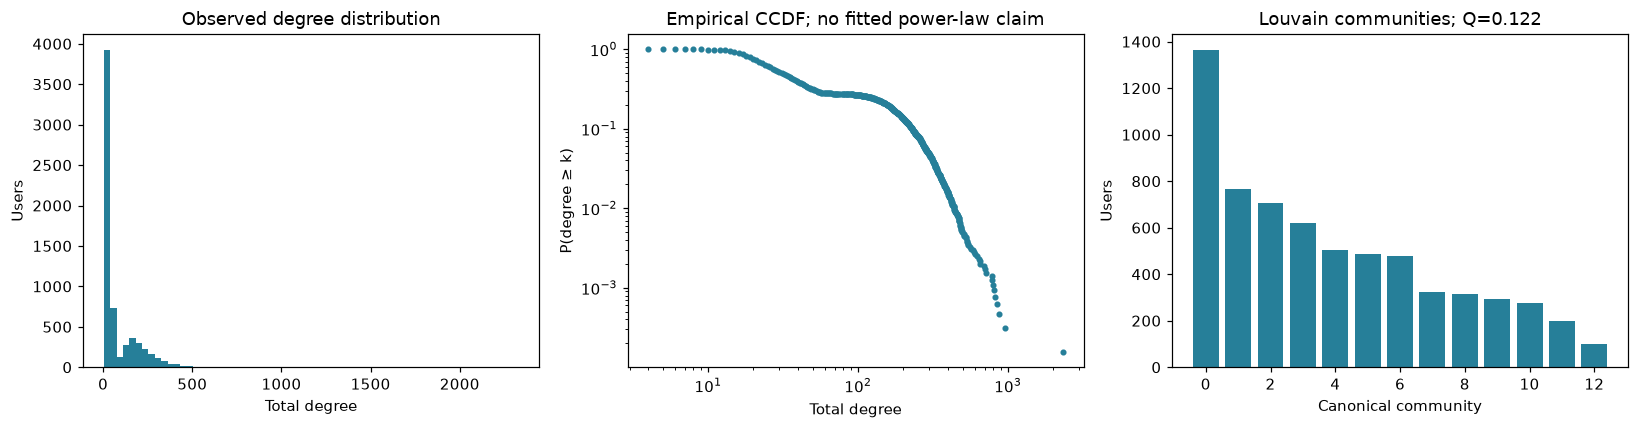

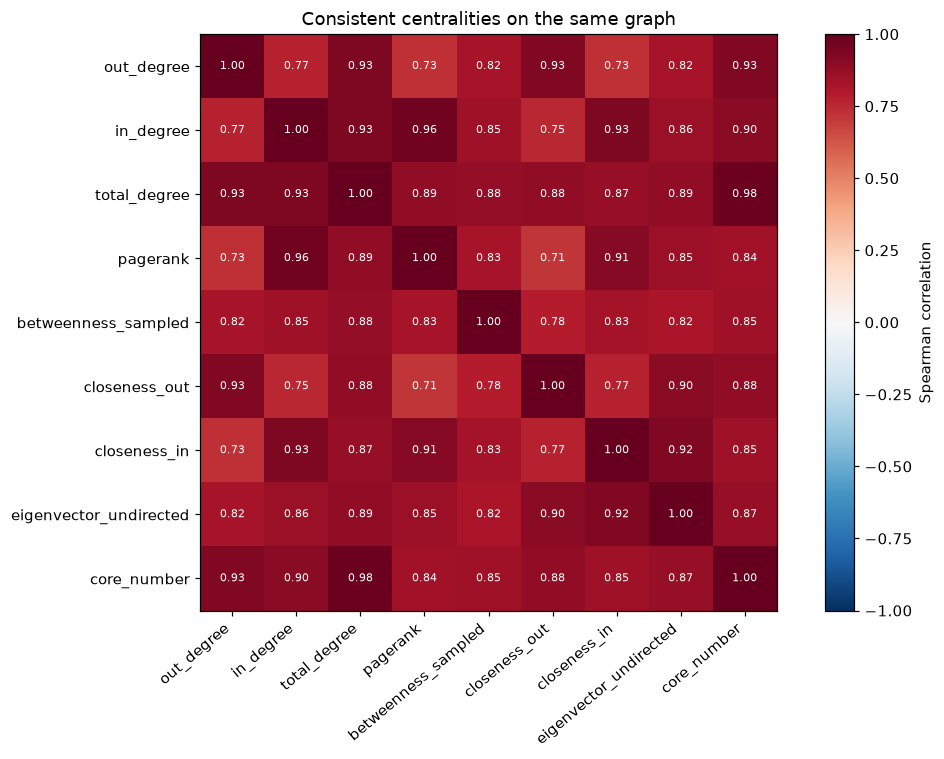

In [5]:
degree=metrics.total_degree.to_numpy()
ks=np.sort(np.unique(degree));ccdf=np.array([(degree>=x).mean() for x in ks])
fig,ax=plt.subplots(1,3,figsize=(15,4))
ax[0].hist(degree,bins=65,color='#267f99');ax[0].set(xlabel='Total degree',ylabel='Users',title='Observed degree distribution')
ax[1].loglog(ks,ccdf,'.',color='#267f99');ax[1].set(xlabel='Total degree',ylabel='P(degree ≥ k)',title='Empirical CCDF; no fitted power-law claim')
ax[2].bar(community_table.community,community_table.nodes,color='#267f99')
ax[2].set(xlabel='Canonical community',ylabel='Users',title=f'Louvain communities; Q={Q:.3f}')
save_figure('01_structure')
cols=[c for c in metrics if c not in ['Label','community']]
corr=metrics[cols].corr(method='spearman')
save_table(corr.reset_index(),'centrality_correlations')
fig,ax=plt.subplots(figsize=(10,7));im=ax.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set_xticks(range(len(cols)),cols,rotation=40,ha='right');ax.set_yticks(range(len(cols)),cols)
for i in range(len(cols)):
    for j in range(len(cols)):ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=7,color='white' if abs(corr.iloc[i,j])>.6 else 'black')
fig.colorbar(im,ax=ax,label='Spearman correlation');ax.set_title('Consistent centralities on the same graph')
save_figure('02_centrality_correlations')


## 6. Build an explicitly observed discussion benchmark

**Purpose and why:** Detection needs timestamps, but the available CSV is not a complete archive of each story. We must distinguish observed events from actual platform-wide events.

**What the next cell does:** Group retained replies by story, record each replier’s first arrival, count distinct observed repliers, and compute the time at which half the retained replies have occurred.

**How to read the output:** An outbreak means at least ten distinct observed repliers. Sources who never reply in the retained rows are not silently counted as timed arrivals. Half-activity is not the time of peak activity.


In [6]:
raw['seconds']=raw.ts.dt.as_unit('ns').astype('int64')/1e9
events={};story_rows=[]
for sid,g in raw.groupby('story_id',sort=True):
    g=g.sort_values(['seconds','comment_id'],kind='stable')
    times=g.seconds.to_numpy();start=times[0]
    first=g.groupby('target_user_hash',sort=True).seconds.min()
    arrivals={u:(t-start)/3600 for u,t in first.items()}
    ev={'start':start,'end':times[-1],'arrivals':arrivals,'participants':len(arrivals),
        'half_h':(times[len(times)//2]-start)/3600,'rows':len(g)}
    events[sid]=ev
    story_rows.append({'story_id':sid,**{k:v for k,v in ev.items() if k!='arrivals'}})
story_table=pd.DataFrame(story_rows).set_index('story_id')
assert len(events)==13772 and sum(v['participants']>=10 for v in events.values())==3418
display(save_table(story_table.reset_index(),'observed_discussions').describe())
print('All exported user identifiers from this point are pseudonyms or readable aliases.')


,start,end,participants,half_h,rows
count,1.377200e+04,1.377200e+04,13772.00000,13772.000000,13772.000000
mean,1.778965e+09,1.779079e+09,13.68494,5.247386,22.720956
std,7.185782e+06,7.217935e+06,28.74325,11.838417,53.171636
min,1.757168e+09,1.757181e+09,1.00000,0.000000,1.000000
25%,1.774402e+09,1.774502e+09,2.00000,0.061528,2.000000
50%,1.780435e+09,1.780553e+09,3.00000,2.047222,4.000000
75%,1.784887e+09,1.785054e+09,9.00000,6.517361,13.000000
max,1.788675e+09,1.788682e+09,255.00000,630.658056,525.000000


All exported user identifiers from this point are pseudonyms or readable aliases.


## 7. Reproduce the historical result and expose the reward defect

**Purpose and why:** Preserve a traceable explanation of the original 52.1% finding before changing the evaluation design.

**What the next cell does:** Score the original twenty sensors on the full data and compare with the saved summary. Reconstruct the old percentile horizon and count arrivals beyond it.

**How to read the output:** The reproduced result is in-sample. In the old code H−t was negative when t>H, so adding a late-only sensor could reduce reward. The new objective clips that contribution to zero.


In [7]:
historical=json.loads((ROOT/'data/detection_summary.json').read_text())
old_sensors=[u2h[u] for u in historical['sensors']]
old_ob={s:e for s,e in events.items() if e['participants']>=10}
times=[];lead=[];per_user=defaultdict(list)
for s,e in old_ob.items():
    for u,t in e['arrivals'].items():per_user[u].append(t)
    seen=[e['arrivals'][u] for u in old_sensors if u in e['arrivals']]
    if seen:times.append(min(seen));lead.append(e['half_h']-min(seen))
fa=sum(any(u in e['arrivals'] for u in old_sensors) for e in events.values() if e['participants']<10)
reproduced={'detection_rate':len(times)/len(old_ob),'mean_delay_h':np.mean(times),
    'median_delay_h':np.median(times),'false_alarms':fa,'precision':len(times)/(len(times)+fa),
    'median_lead_h':np.median(lead),'pct_before_half':100*np.mean(np.array(lead)>0)}
assert all(np.isclose(v,historical[k]) for k,v in reproduced.items())
old_horizon=float(np.percentile([max(v) for v in per_user.values()],95))
late_count=sum(t>old_horizon for vals in per_user.values() for t in vals)
display(save_table(pd.DataFrame(reproduced.items(),columns=['historical_in_sample_metric','value']),'historical_reproduction'))
print(f'Historical horizon: {old_horizon:.2f}h; {late_count} user/story arrivals exceed it.')
print('PASS: all seven historical metrics reproduced. This is not a future-performance estimate.')


,historical_in_sample_metric,value
0,detection_rate,0.521065
1,mean_delay_h,5.837060
2,median_delay_h,2.630000
3,false_alarms,431.000000
4,precision,0.805154
5,median_lead_h,2.445556
6,pct_before_half,77.596856


Historical horizon: 138.73h; 392 user/story arrivals exceed it.
PASS: all seven historical metrics reproduced. This is not a future-performance estimate.


## 8. Chronological train, validation and untouched test sets

**Purpose and why:** The original optimizer selected sensors and evaluated them on the same outbreaks, which can overestimate future performance.

**What the next cell does:** Use the 60th and 80th percentiles of observed story-start times as fixed chronological boundaries. Purge stories that cross a boundary. Use training data only for graph construction, horizon and sensor selection.

**How to read the output:** Validation selects an illustrative budget; test remains unused until the evaluation cell. Purging avoids sharing a discussion across splits, but may preferentially exclude long discussions. Test-end censoring and original population-selection bias remain.


In [8]:
cut1,cut2=np.quantile(story_table.start,[.6,.8])
split_ids={
    'train':story_table.index[story_table.end<cut1].tolist(),
    'validation':story_table.index[(story_table.start>=cut1)&(story_table.end<cut2)].tolist(),
    'test':story_table.index[story_table.start>=cut2].tolist()}
used=set().union(*map(set,split_ids.values()))
purged=sorted(set(events)-used)
assert all(set(split_ids[a]).isdisjoint(split_ids[b]) for a,b in [('train','validation'),('train','test'),('validation','test')])
assert story_table.loc[split_ids['train'],'end'].max()<story_table.loc[split_ids['validation'],'start'].min()
assert story_table.loc[split_ids['validation'],'end'].max()<story_table.loc[split_ids['test'],'start'].min()
train_rows=raw[raw.story_id.isin(split_ids['train'])]
G_train=nx.DiGraph()
for (u,v),w in train_rows.groupby(['source_user_hash','target_user_hash'],sort=True).size().items():
    G_train.add_edge(u,v,weight=int(w))
candidates=sorted(G_train)
train_ob=[s for s in split_ids['train'] if events[s]['participants']>=10]
H=float(np.percentile([t for s in train_ob for t in events[s]['arrivals'].values()],95))
assert H>0 and len(candidates)>=K_MAX
split_table=pd.DataFrame([{'split':name,'stories':len(ids),
    'outbreaks':sum(events[s]['participants']>=10 for s in ids),
    'first_observed_UTC':str(pd.to_datetime(min(events[s]['start'] for s in ids),unit='s',utc=True)),
    'last_observed_UTC':str(pd.to_datetime(max(events[s]['end'] for s in ids),unit='s',utc=True))}
    for name,ids in split_ids.items()])
display(save_table(split_table,'chronological_splits'))
print(f'Purged {len(purged)} boundary-crossing discussions. Training horizon={H:.2f}h; candidates={len(candidates)}.')
save_table(pd.DataFrame({'story_id':purged}),'purged_discussions')
protocol={'cut1_utc':str(pd.to_datetime(cut1,unit='s',utc=True)),
          'cut2_utc':str(pd.to_datetime(cut2,unit='s',utc=True)),
          'horizon_hours':H,'min_participants':10,'k_prespecified':K_REPORT,
          'candidate_policy':'all training graph users','purged_stories':len(purged)}
(OUT/'detection_protocol.json').write_text(json.dumps(protocol,indent=2))


,split,stories,outbreaks,first_observed_UTC,last_observed_UTC
0,train,8145,1382,2025-09-06 14:06:06+00:00,2026-06-25 04:50:20+00:00
1,validation,2614,847,2026-06-25 05:15:57+00:00,2026-08-01 19:29:00+00:00
2,test,2755,988,2026-08-01 19:32:11+00:00,2026-09-06 08:05:31+00:00


Purged 258 boundary-crossing discussions. Training horizon=36.18h; candidates=6071.


262

## 9. Correct submodular reward and a reusable, tested CELF implementation

**Purpose and why:** CELF is valid for a deterministic monotone submodular objective. Nonnegative per-discussion rewards ensure that property here.

**What the next cell does:** Represent user contributions as a sparse matrix. Implement ordinary greedy and stamped heap-based CELF with deterministic tie-breaking. Test both on small coverage examples and a late-arrival example.

**How to read the output:** For a set S, F(S)=mean over outbreaks of max(0, 1−min arrival(S)/H); absence contributes zero. Each term is a maximum of nonnegative constants, hence monotone and submodular. The 1−1/e guarantee concerns the empirical training objective and stated candidate set, not unseen traffic.


In [9]:
def reward_matrix(ids,users,horizon,threshold=10):
    outbreaks=[s for s in ids if events[s]['participants']>=threshold]
    lookup={u:i for i,u in enumerate(users)};rr=[];cc=[];vv=[]
    for i,s in enumerate(outbreaks):
        for u,t in events[s]['arrivals'].items():
            value=max(0.,1-t/horizon)
            if u in lookup and value>0:rr.append(i);cc.append(lookup[u]);vv.append(value)
    return sparse.csc_matrix((vv,(rr,cc)),shape=(len(outbreaks),len(users))),outbreaks

class SparseCoverage:
    def __init__(self,matrix):
        self.matrix=matrix;self.covered=np.zeros(matrix.shape[0])
    def gain(self,c):
        lo,hi=self.matrix.indptr[c:c+2];ix=self.matrix.indices[lo:hi];val=self.matrix.data[lo:hi]
        return float(np.maximum(val-self.covered[ix],0).sum())
    def add(self,c):
        lo,hi=self.matrix.indptr[c:c+2];ix=self.matrix.indices[lo:hi]
        self.covered[ix]=np.maximum(self.covered[ix],self.matrix.data[lo:hi])

def select(factory,candidate_indices,k,lazy=True):
    obj=factory();chosen=[];selected=set();evaluations=0;history=[];t=perf_counter()
    candidates_=sorted(candidate_indices)
    if lazy:
        heap=[(-obj.gain(c),c,0) for c in candidates_];evaluations=len(heap);heapq.heapify(heap)
    while len(chosen)<min(k,len(candidates_)):
        if lazy:
            neg,c,stamp=heapq.heappop(heap)
            if stamp!=len(chosen):
                heapq.heappush(heap,(-obj.gain(c),c,len(chosen)));evaluations+=1;continue
            gain=-neg
        else:
            scored=[(obj.gain(c),c) for c in candidates_ if c not in selected]
            evaluations+=len(scored);gain,c=max(scored,key=lambda x:(x[0],-x[1]))
        assert gain>=-1e-8
        obj.add(c);chosen.append(c);selected.add(c)
        history.append({'k':len(chosen),'gain':gain,'evaluations':evaluations,'selection_s':perf_counter()-t})
    return chosen,pd.DataFrame(history)

toy_matrix=sparse.csc_matrix([[1.,0.,.5,0.],[0.,1.,.5,0.],[0.,0.,1.,0.]])
a,_=select(lambda:SparseCoverage(toy_matrix),range(4),4,True)
b,_=select(lambda:SparseCoverage(toy_matrix),range(4),4,False)
assert a==b and len(set(a))==4
assert max(0.,1-200/100)==0. # late arrival cannot reduce reward
# Exhaustive diminishing-returns/monotonicity checks on the toy objective.
from itertools import combinations
sets=[set(c) for k in range(5) for c in combinations(range(4),k)]
def toy_value(S):return np.max(toy_matrix.toarray()[:,sorted(S)],axis=1).sum() if S else 0.
for A in sets:
    for B in sets:
        if A<=B:
            assert toy_value(A)<=toy_value(B)+1e-12
            for u in set(range(4))-B:
                assert toy_value(A|{u})-toy_value(A)+1e-12>=toy_value(B|{u})-toy_value(B)
R_train,_=reward_matrix(split_ids['train'],candidates,H)
detect_indices,detect_hist=select(lambda:SparseCoverage(R_train),range(len(candidates)),K_MAX)
greedy_indices,greedy_hist=select(lambda:SparseCoverage(R_train),range(len(candidates)),5,False)
assert detect_indices[:5]==greedy_indices
detector=[candidates[i] for i in detect_indices]
save_table(detect_hist,'detection_selection_history')
print('PASS: nonnegative rewards, monotonicity, diminishing returns, unique seeds, and real-data CELF = Greedy at k=5.')
display(detect_hist[detect_hist.k.isin(K_VALUES)])


PASS: nonnegative rewards, monotonicity, diminishing returns, unique seeds, and real-data CELF = Greedy at k=5.


,k,gain,evaluations,selection_s
0,1,68.281709,6071,0.017143
4,5,35.584381,6166,0.017520
9,10,25.870459,6471,0.018620
14,15,20.738085,6859,0.020004
19,20,17.320554,7251,0.021393
24,25,14.783771,7625,0.022966
29,30,12.793530,7963,0.024141


## 10. Training-only structural and activity baselines

**Purpose and why:** The old detector skipped structural baselines because its user identifiers differed from graph identifiers. Using full-period centralities in a holdout would introduce future information.

**What the next cell does:** Compute metrics from the training graph only, rank candidates by activity and graph measures, and generate 100 independent random sensor rankings.

**How to read the output:** All methods have the same eligible population and budget. Top-reach counts training outbreaks; eigenvector and core use the explicitly summed undirected training graph.


In [10]:
t=perf_counter();train_metrics=centralities(G_train)
save_table(train_metrics.reset_index(),'training_node_metrics')
reach=Counter(u for s in train_ob for u in events[s]['arrivals'])
def ranked(values,users,k):return sorted(users,key=lambda u:(-values.get(u,0),u))[:k]
sensor_methods={'CELF-detect':detector,'Top-reach':ranked(reach,candidates,K_MAX)}
for name,col in [('Out-degree','out_degree'),('PageRank','pagerank'),('Betweenness','betweenness_sampled'),
                 ('Eigenvector-undirected','eigenvector_undirected'),('Closeness-out','closeness_out'),('K-core','core_number')]:
    sensor_methods[name]=ranked(train_metrics[col].to_dict(),candidates,K_MAX)
random_sensor_sets=[random.Random(10000+i).sample(candidates,K_MAX) for i in range(RANDOM_REPEATS)]
save_table(pd.DataFrame([{'method':m,'rank':i,'Id':u,'Label':labels[u]} for m,S in sensor_methods.items()
                        for i,u in enumerate(S,1)]),'training_sensor_rankings')
assert all(set(S)<=set(candidates) for S in sensor_methods.values())
print(f'Training baselines completed in {perf_counter()-t:.1f}s. No validation/test edges were used.')


Training baselines completed in 13.7s. No validation/test edges were used.


## 11. Validation metrics and budget choice before test access

**Purpose and why:** Coverage, delay, precision and early reward measure different things. Delays conditional on detection can make a method look fast simply because it misses hard discussions.

**What the next cell does:** Define common evaluation functions. Score validation only; retain k=20 as the pre-specified historical comparison and select a secondary budget using 95% of the best validation reward within the tested budgets.

**How to read the output:** Detection at any observed time and detection within H are separate columns. Mean capped outbreak delay assigns H to misses, so coverage and speed are jointly represented. Precision labels an alert using the discussion’s eventual observed size.


In [11]:
def outcomes(S,ids,horizon,threshold=10):
    rows=[]
    for sid in ids:
        e=events[sid];tt=[e['arrivals'][u] for u in S if u in e['arrivals']]
        delay=min(tt) if tt else np.inf
        rows.append({'story_id':sid,'outbreak':e['participants']>=threshold,'delay_h':delay,
                     'detected':np.isfinite(delay),'within_horizon':delay<=horizon,
                     'reward':max(0.,1-delay/horizon),
                     'lead_half_h':e['half_h']-delay,'start':e['start']})
    return pd.DataFrame(rows)

def summarize(o,horizon):
    ob=o[o.outbreak];found=ob[ob.detected];tp=int(found.shape[0]);fp=int((~o.outbreak&o.detected).sum())
    within=ob[ob.within_horizon]
    return {'outbreaks':len(ob),'detected_outbreaks':tp,'detection_rate':tp/len(ob) if len(ob) else np.nan,
        'detection_within_horizon':ob.within_horizon.mean(),'mean_reward':ob.reward.mean(),
        'mean_capped_delay_h':np.minimum(ob.delay_h,horizon).mean(),
        'mean_delay_detected_h':found.delay_h.mean(),'median_delay_detected_h':found.delay_h.median(),
        'precision':tp/(tp+fp) if tp+fp else np.nan,'false_alarms':fp,
        'median_lead_half_h':found.lead_half_h.median(),
        'before_half_fraction_of_detected':(found.lead_half_h>0).mean() if tp else np.nan}

validation_rows=[]
for method,S in sensor_methods.items():
    for k in K_VALUES:validation_rows.append({'method':method,'k':k,**summarize(outcomes(S[:k],split_ids['validation'],H),H)})
validation=pd.DataFrame(validation_rows)
curve=validation[validation.method=='CELF-detect'].sort_values('k')
best_reward=curve.mean_reward.max()
K_VALIDATED=int(curve.loc[curve.mean_reward>=.95*best_reward,'k'].iloc[0])
save_table(validation,'validation_detection_results')
protocol['validation_selected_k']=K_VALIDATED
protocol['budget_rule']='smallest tested k achieving >=95% of maximum validation early reward'
(OUT/'detection_protocol.json').write_text(json.dumps(protocol,indent=2))
display(curve[['k','detection_rate','detection_within_horizon','mean_reward','precision']])
print(f'Frozen budgets: prespecified k={K_REPORT}; validation-selected k={K_VALIDATED}. No test result used in selection.')


,k,detection_rate,detection_within_horizon,mean_reward,precision
0,1,0.089728,0.086187,0.065423,1.000000
1,5,0.127509,0.125148,0.098582,0.864000
2,10,0.154664,0.152302,0.122471,0.856209
3,15,0.219599,0.214876,0.178186,0.849315
4,20,0.263282,0.259740,0.219126,0.844697
5,25,0.299882,0.295159,0.249807,0.830065
6,30,0.347107,0.341204,0.295195,0.814404


Frozen budgets: prespecified k=20; validation-selected k=30. No test result used in selection.


## 12. Held-out test evaluation with repeated random baselines

**Purpose and why:** This is the first performance evaluation on the held-out stories. Sensor choices and budgets are now frozen.

**What the next cell does:** Evaluate every method at the predeclared budget grid, then 100 random sets per budget. Export a separate selection-variability table for random baselines.

**How to read the output:** The random 2.5–97.5 percentiles describe variation across random sensor selections, not confidence intervals for future Hacker News traffic. The new test figures need not match the old in-sample headline.


In [12]:
test_ids=split_ids['test'];test_rows=[];random_rows=[];test_outcomes={}
for method,S in sensor_methods.items():
    for k in K_VALUES:
        o=outcomes(S[:k],test_ids,H)
        test_rows.append({'method':method,'k':k,**summarize(o,H)})
        if k==K_REPORT:test_outcomes[method]=o
for rep,S in enumerate(random_sensor_sets):
    for k in K_VALUES:random_rows.append({'replicate':rep,'k':k,**summarize(outcomes(S[:k],test_ids,H),H)})
test_results=pd.DataFrame(test_rows);random_results=pd.DataFrame(random_rows)
random_summary=[]
for k,g in random_results.groupby('k'):
    for col in ['detection_rate','detection_within_horizon','mean_reward','precision','mean_capped_delay_h']:
        random_summary.append({'k':k,'metric':col,'mean':g[col].mean(),
            'selection_p025':g[col].quantile(.025),'selection_p975':g[col].quantile(.975)})
save_table(test_results,'test_detection_results');save_table(random_results,'random_detection_replicates')
save_table(pd.DataFrame(random_summary),'random_selection_variability')
display(test_results[test_results.k==K_REPORT][['method','k','detection_rate','detection_within_horizon','median_delay_detected_h','precision','mean_reward']])
display(random_results[random_results.k==K_REPORT][['detection_rate','precision','mean_reward']].agg(['mean','std']))
generalization=pd.DataFrame([{'split':split,'method':method,'k':K_REPORT,
    **summarize(outcomes(S[:K_REPORT],ids,H),H)}
    for split,ids in split_ids.items() for method,S in sensor_methods.items()])
save_table(generalization,'train_validation_test_comparison')
display(generalization.pivot(index='method',columns='split',values='mean_reward'))
print('The cross-split table is descriptive; these test results do not trigger retraining or retuning.')
test_seen_users=set(u for s in test_ids for u in events[s]['arrivals'])
print(f'Test repliers unseen in the training graph: {len(test_seen_users-set(candidates))}/{len(test_seen_users)}.')


,method,k,detection_rate,detection_within_horizon,median_delay_detected_h,precision,mean_reward
4,CELF-detect,20,0.268219,0.264170,3.163056,0.866013,0.217761
11,Top-reach,20,0.456478,0.444332,3.566944,0.788462,0.368819
18,Out-degree,20,0.392713,0.387652,2.042639,0.815126,0.339597
25,PageRank,20,0.453441,0.435223,3.721250,0.797153,0.362698
32,Betweenness,20,0.421053,0.401822,4.188333,0.761905,0.330431
39,Eigenvector-undirected,20,0.308704,0.299595,3.464167,0.833333,0.251614
46,Closeness-out,20,0.390688,0.385628,2.527083,0.842795,0.334409
53,K-core,20,0.279352,0.277328,3.721250,0.814159,0.230812


,detection_rate,precision,mean_reward
mean,0.131872,0.882235,0.102736
std,0.040993,0.047626,0.033290


split,test,train,validation
method,,,
Betweenness,0.330431,0.312578,0.277849
CELF-detect,0.217761,0.429956,0.219126
Closeness-out,0.334409,0.315962,0.287693
Eigenvector-undirected,0.251614,0.298768,0.214735
K-core,0.230812,0.246223,0.231153
Out-degree,0.339597,0.304861,0.238311
PageRank,0.362698,0.285624,0.283674
Top-reach,0.368819,0.344461,0.335990


The cross-split table is descriptive; these test results do not trigger retraining or retuning.
Test repliers unseen in the training graph: 291/5653.


## 13. Paired uncertainty and a fair delay comparison

**Purpose and why:** An apparent advantage may be small relative to sampling uncertainty, and conditional delay must be compared on the same discussions.

**What the next cell does:** Bootstrap the paired CELF-minus-Top-reach difference across test outbreaks and, separately, across calendar-week blocks. Compare delays on the intersection detected by both methods.

**How to read the output:** Intervals are exploratory: discussion/user dependence and few time blocks limit inferential strength. A positive interval does not prove causal influence or eliminate population-sampling bias.


In [13]:
a=test_outcomes['CELF-detect'];b=test_outcomes['Top-reach']
assert a.story_id.equals(b.story_id)
ob=a.outbreak.to_numpy();rng=np.random.default_rng(5151)
differences={
    'detection_rate':a.loc[ob,'detected'].to_numpy(float)-b.loc[ob,'detected'].to_numpy(float),
    'within_horizon':a.loc[ob,'within_horizon'].to_numpy(float)-b.loc[ob,'within_horizon'].to_numpy(float),
    'early_reward':a.loc[ob,'reward'].to_numpy()-b.loc[ob,'reward'].to_numpy()}
weeks=pd.to_datetime(a.loc[ob,'start'],unit='s',utc=True).dt.strftime('%G-%V').to_numpy()
blocks=[np.flatnonzero(weeks==w) for w in sorted(set(weeks))]
interval_rows=[]
for metric,delta in differences.items():
    iid=np.array([delta[rng.integers(0,len(delta),len(delta))].mean() for _ in range(BOOTSTRAPS)])
    block=np.array([delta[np.concatenate([blocks[i] for i in rng.integers(0,len(blocks),len(blocks))])].mean()
                    for _ in range(BOOTSTRAPS)])
    for scheme,values in [('story bootstrap',iid),('calendar-week block bootstrap',block)]:
        interval_rows.append({'metric':metric,'resampling':scheme,'difference':delta.mean(),
            'lower_95':np.quantile(values,.025),'upper_95':np.quantile(values,.975),'test_week_blocks':len(blocks)})
intervals=pd.DataFrame(interval_rows)
display(save_table(intervals,'paired_detection_intervals'))
common=ob&a.detected.to_numpy()&b.detected.to_numpy()
common_delays=pd.DataFrame({'method':['CELF-detect','Top-reach'],
    'common_outbreaks':[int(common.sum())]*2,
    'median_delay_h':[a.loc[common,'delay_h'].median(),b.loc[common,'delay_h'].median()],
    'mean_delay_h':[a.loc[common,'delay_h'].mean(),b.loc[common,'delay_h'].mean()]})
display(save_table(common_delays,'common_detected_delay_comparison'))


,metric,resampling,difference,lower_95,upper_95,test_week_blocks
0,detection_rate,story bootstrap,-0.188259,-0.220673,-0.157869,6
1,detection_rate,calendar-week block bootstrap,-0.188259,-0.238074,-0.135522,6
2,within_horizon,story bootstrap,-0.180162,-0.211538,-0.148785,6
3,within_horizon,calendar-week block bootstrap,-0.180162,-0.234607,-0.127188,6
4,early_reward,story bootstrap,-0.151058,-0.178273,-0.123530,6
5,early_reward,calendar-week block bootstrap,-0.151058,-0.190066,-0.112304,6


,method,common_outbreaks,median_delay_h,mean_delay_h
0,CELF-detect,208,4.045417,8.617755
1,Top-reach,208,2.877222,7.413126


## 14. Sensitivity to outbreak definition and detection horizon

**Purpose and why:** The ten-participant threshold and time horizon are modelling choices rather than natural constants.

**What the next cell does:** Refit sensors on training data at thresholds 5, 10 and 20 and horizon multipliers 0.5, 1 and 2. Evaluate these alternatives on validation only.

**How to read the output:** These rows describe sensitivity; they do not retune the frozen test model. Rates across thresholds have different denominators and are not directly interchangeable.


In [14]:
sensitivity_rows=[]
for threshold in [5,10,20]:
    for multiplier in [.5,1.,2.]:
        h=H*multiplier;matrix,obs=reward_matrix(split_ids['train'],candidates,h,threshold)
        idx,_=select(lambda:SparseCoverage(matrix),range(len(candidates)),K_REPORT)
        S=[candidates[i] for i in idx]
        sensitivity_rows.append({'threshold':threshold,'horizon_multiplier':multiplier,'horizon_h':h,
            'train_outbreaks':len(obs),'overlap_with_primary_20':len(set(S)&set(detector[:K_REPORT])),
            **summarize(outcomes(S,split_ids['validation'],h,threshold),h)})
sensitivity=pd.DataFrame(sensitivity_rows)
display(save_table(sensitivity,'validation_sensitivity')[['threshold','horizon_multiplier','outbreaks','detection_rate','precision','mean_reward','overlap_with_primary_20']])


,threshold,horizon_multiplier,outbreaks,detection_rate,precision,mean_reward,overlap_with_primary_20
0,5,0.5,1365,0.161172,0.876494,0.123023,9
1,5,1.0,1365,0.167766,0.901575,0.141763,11
2,5,2.0,1365,0.168498,0.938776,0.152764,9
3,10,0.5,847,0.275089,0.811847,0.197561,10
4,10,1.0,847,0.263282,0.844697,0.219126,20
5,10,2.0,847,0.317591,0.810241,0.286894,14
6,20,0.5,398,0.580402,0.571782,0.429875,7
7,20,1.0,398,0.597990,0.641509,0.491303,6
8,20,2.0,398,0.615578,0.603448,0.563648,7


## 15. Offline alert ledger and held-out arrival-position validation

**Purpose and why:** A practical output should identify which observed events would trigger an alert, without presenting retrospective labels as information available at alert time.

**What the next cell does:** Build a pseudonym-only test alert ledger, calculate warning relative to the tenth distinct observed participant, and compare sensor arrival positions on test outbreaks.

**How to read the output:** Eventual outbreak labels are evaluation labels, not predictions. Detection sensors are selected on training only. This is an offline replay, not a deployed monitor. Arrival-position means are shown both per participation and per user.


In [15]:
ledger=[];test_positions=defaultdict(list)
for sid in test_ids:
    e=events[sid];ordered=sorted(e['arrivals'].items(),key=lambda x:(x[1],x[0]))
    available=[(t,u) for u,t in ordered if u in set(detector[:K_REPORT])]
    if available:
        delay,u=min(available);cross=ordered[9][1] if len(ordered)>=10 else np.nan
        ledger.append({'story_id':sid,'sensor_Id':u,'sensor_label':labels[u],
            'alert_UTC':str(pd.to_datetime(e['start']+delay*3600,unit='s',utc=True)),
            'delay_h':delay,'eventual_observed_participants':len(ordered),
            'eventual_outbreak':len(ordered)>=10,'lead_before_tenth_participant_h':cross-delay,
            'within_horizon':delay<=H})
    if len(ordered)>=10:
        for i,(u,t) in enumerate(ordered):test_positions[u].append(i/(len(ordered)-1))
alert_ledger=save_table(pd.DataFrame(ledger),'test_alert_ledger')
arrival_rows=[]
for method in ['CELF-detect','Top-reach','Out-degree','PageRank']:
    S=sensor_methods[method][:K_REPORT];present=[u for u in S if test_positions.get(u)]
    vals=[x for u in present for x in test_positions[u]]
    arrival_rows.append({'method':method,'selected_users':len(S),'users_observed_in_test_outbreaks':len(present),
        'participation_weighted_mean':np.mean(vals) if vals else np.nan,
        'user_weighted_mean':np.mean([np.mean(test_positions[u]) for u in present]) if present else np.nan,
        'first_decile_fraction':np.mean(np.array(vals)<=.1) if vals else np.nan,
        'mean_test_outbreaks_per_selected_user':sum(len(test_positions.get(u,[])) for u in S)/len(S)})
arrival_validation=pd.DataFrame(arrival_rows)
display(save_table(arrival_validation,'heldout_arrival_validation'))
test_days=(max(events[s]['end'] for s in test_ids)-cut2)/86400
true_alerts=alert_ledger[alert_ledger.eventual_outbreak]
print(f'Observed replay alerts: {len(ledger)} over {test_days:.1f} days; {len(ledger)/test_days:.2f} per calendar day.')
print(f'Of detected outbreaks, {(true_alerts.lead_before_tenth_participant_h>0).mean():.1%} were flagged before their tenth observed participant.')


,method,selected_users,users_observed_in_test_outbreaks,participation_weighted_mean,user_weighted_mean,first_decile_fraction,mean_test_outbreaks_per_selected_user
0,CELF-detect,20,16,0.469069,0.428189,0.129518,16.60
1,Top-reach,20,18,0.542842,0.543864,0.097222,36.00
2,Out-degree,20,20,0.421158,0.440891,0.149281,27.80
3,PageRank,20,18,0.518809,0.508874,0.109531,35.15


Observed replay alerts: 306 over 35.5 days; 8.61 per calendar day.
Of detected outbreaks, 27.9% were flagged before their tenth observed participant.


## 16. Holdout figures with uncertainty and explicit denominators

**Purpose and why:** Replace the single retrospective headline with separate test coverage, alert quality, miss-adjusted delay and validation sensitivity.

**What the next cell does:** Plot held-out results, random-selection variability, paired uncertainty and sensitivity. Save figures with readable labels.

**How to read the output:** Shading around Random is a sensor-selection percentile band. The paired interval plot is CELF minus Top-reach; crossing zero means the direction is uncertain under that resampling scheme.


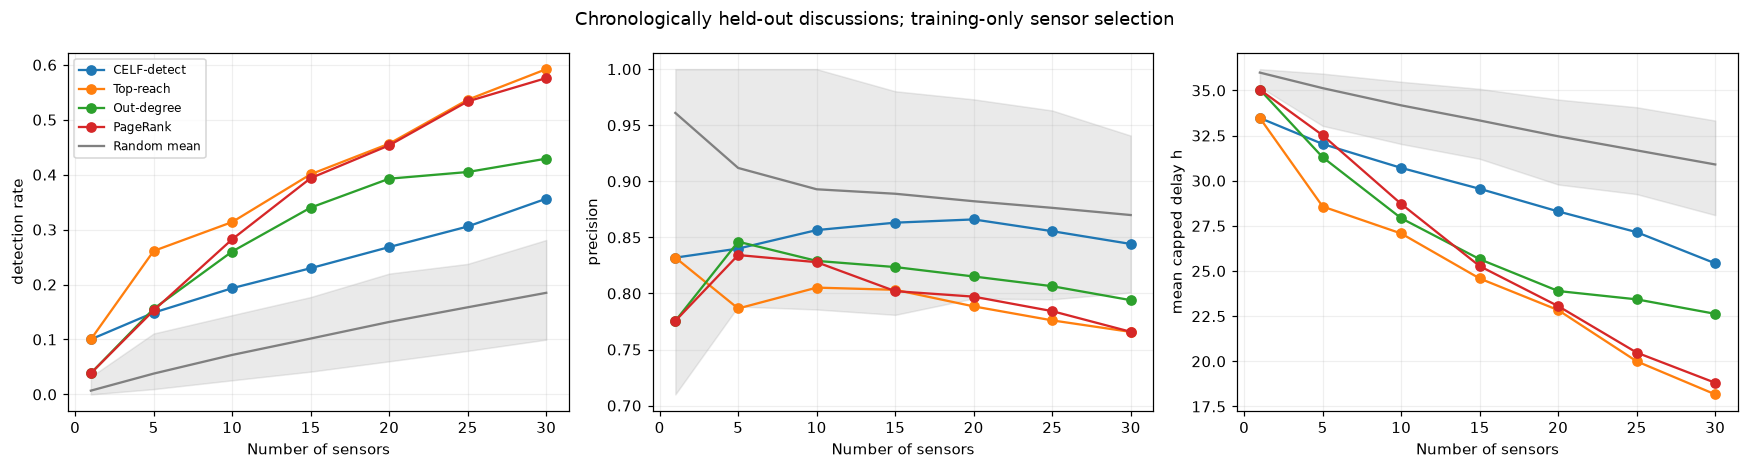

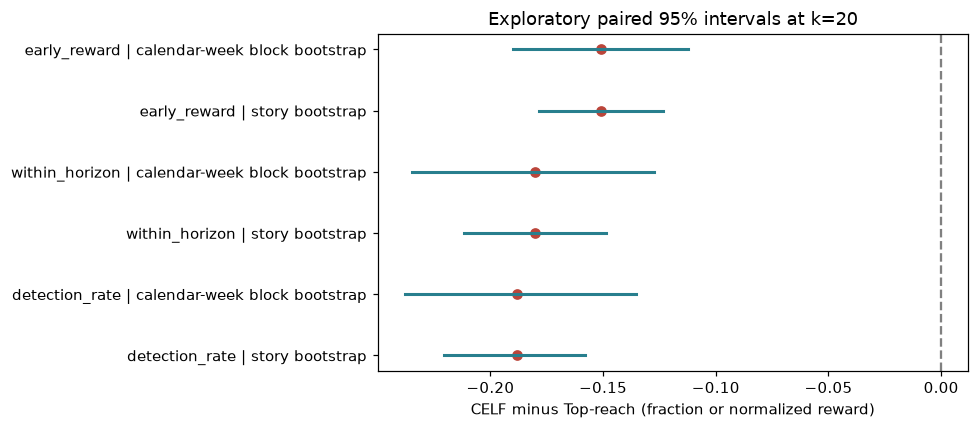

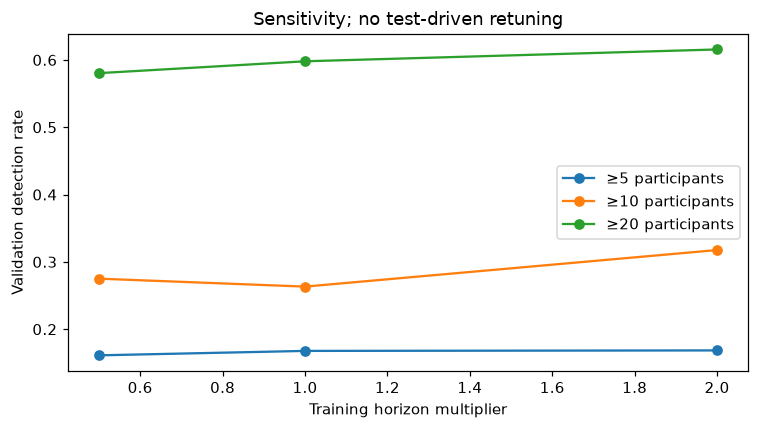

In [16]:
fig,axes=plt.subplots(1,3,figsize=(16,4.3))
for method in ['CELF-detect','Top-reach','Out-degree','PageRank']:
    d=test_results[test_results.method==method].sort_values('k')
    for ax,col in zip(axes,['detection_rate','precision','mean_capped_delay_h']):ax.plot(d.k,d[col],marker='o',label=method)
rand=pd.DataFrame(random_summary)
for ax,col in zip(axes,['detection_rate','precision','mean_capped_delay_h']):
    d=rand[rand.metric==col].sort_values('k');ax.plot(d.k,d['mean'],color='gray',label='Random mean')
    ax.fill_between(d.k,d.selection_p025,d.selection_p975,color='gray',alpha=.16)
    ax.set(xlabel='Number of sensors',ylabel=col.replace('_',' '));ax.grid(alpha=.2)
axes[0].legend(fontsize=8);fig.suptitle('Chronologically held-out discussions; training-only sensor selection')
save_figure('03_heldout_detection')
fig,ax=plt.subplots(figsize=(9,4))
for i,r in intervals.iterrows():
    ax.plot([r.lower_95,r.upper_95],[i,i],color='#287f8e',lw=2);ax.scatter(r.difference,i,color='#bb453a')
ax.axvline(0,color='gray',ls='--');ax.set_yticks(range(len(intervals)),intervals.metric+' | '+intervals.resampling)
ax.set(xlabel='CELF minus Top-reach (fraction or normalized reward)',title='Exploratory paired 95% intervals at k=20')
save_figure('04_paired_uncertainty')
fig,ax=plt.subplots(figsize=(7,4))
for threshold,d in sensitivity.groupby('threshold'):ax.plot(d.horizon_multiplier,d.detection_rate,marker='o',label=f'≥{threshold} participants')
ax.set(xlabel='Training horizon multiplier',ylabel='Validation detection rate',title='Sensitivity; no test-driven retuning');ax.legend()
save_figure('05_validation_sensitivity')


## 17. Define comparable influence experiments

**Purpose and why:** The earlier RIS merge compared 200-world scores with 500-world scores, and the report omitted the probability cap. Here the primary model is standard uncapped Weighted Cascade.

**What the next cell does:** Create stable integer node IDs, explicit probability arrays and live-world sampling. Use all nodes as CELF candidates; keep selection worlds separate from test worlds.

**How to read the output:** Primary probabilities are 1/in-degree(target). The historical min(1/in-degree,0.5) and weight-derived model are sensitivity cases. Influence here is simulated reach, not demonstrated adoption.


In [17]:
N=len(node_ids);node_index={u:i for i,u in enumerate(node_ids)}
edge_list=sorted(G.edges())
src=np.array([node_index[u] for u,v in edge_list],dtype=np.int32)
dst=np.array([node_index[v] for u,v in edge_list],dtype=np.int32)
weight=np.array([G[u][v]['weight'] for u,v in edge_list])
indeg=np.array([G.in_degree(u) for u in node_ids])
P_standard=1./indeg[dst]
P_capped=np.minimum(P_standard,.5)
P_weight=np.minimum(1-(1-.03)**weight,.5)
assert np.all((P_standard>0)&(P_standard<=1))

def live_world(probabilities,rng):
    live=[[] for _ in range(N)]
    for i in np.flatnonzero(rng.random(len(src))<probabilities):live[int(src[i])].append(int(dst[i]))
    return live

def reached(live,seeds):
    active=set(seeds);frontier=list(seeds)
    for u in frontier:
        for v in live[u]:
            if v not in active:active.add(v);frontier.append(v)
    return active

probability_table=pd.DataFrame([{'model':name,'mean_p':p.mean(),'max_p':p.max(),'p_equals_one_edges':int((p==1).sum())}
    for name,p in [('standard WC',P_standard),('historical capped WC',P_capped),('weight-derived capped',P_weight)]])
display(save_table(probability_table,'probability_models'))
print(f'{int(np.sum(P_standard!=P_capped))} edges change when the historical cap is removed.')


,model,mean_p,max_p,p_equals_one_edges
0,standard WC,0.024745,1.0,18
1,historical capped WC,0.024710,0.5,0
2,weight-derived capped,0.035920,0.5,0


18 edges change when the historical cap is removed.


## 18. Fixed-world CELF and Greedy with exact bitset coverage

**Purpose and why:** Fixed live worlds make the empirical objective deterministic. Caching reachable sets removes repeated traversal without changing that objective.

**What the next cell does:** Precompute each candidate’s reachable-node bitset in each of 200 selection worlds. Run CELF to 30 seeds and ordinary Greedy to five, with identical tie rules and candidate sets.

**How to read the output:** The assertion establishes equality on this empirical objective. The approximation guarantee is relative to the optimum of that finite-world objective; independent evaluation below estimates model spread. Timing includes shared preprocessing separately.


In [18]:
t=perf_counter();rng=np.random.default_rng(TRAIN_WORLD_SEED)
bits=[1<<i for i in range(N)]
reach_cache=[[] for _ in range(N)]
for world_no in range(MC_TRAIN):
    live=live_world(P_standard,rng)
    for u in range(N):reach_cache[u].append(sum(bits[v] for v in reached(live,[u])))
    if (world_no+1)%50==0:print(f'Cached {world_no+1}/{MC_TRAIN} selection worlds',flush=True)
cache_seconds=perf_counter()-t

class MaskCoverage:
    def __init__(self,cache):self.cache=cache;self.covered=[0]*len(cache[0])
    def gain(self,c):return sum((mask & ~old).bit_count() for mask,old in zip(self.cache[c],self.covered))
    def add(self,c):self.covered=[old|mask for old,mask in zip(self.covered,self.cache[c])]

im_indices,im_hist=select(lambda:MaskCoverage(reach_cache),range(N),K_MAX)
greedy_im,greedy_im_hist=select(lambda:MaskCoverage(reach_cache),range(N),5,False)
assert im_indices[:5]==greedy_im
assert np.all(np.diff(im_hist.gain)<=0)
singleton_train=np.array([sum(x.bit_count() for x in masks)/MC_TRAIN for masks in reach_cache])
timing=pd.DataFrame([
    {'method':'CELF','k':5,'evaluations':int(im_hist.iloc[4].evaluations),'preprocessing_s':cache_seconds,'selection_s':im_hist.iloc[4].selection_s},
    {'method':'Greedy','k':5,'evaluations':int(greedy_im_hist.iloc[-1].evaluations),'preprocessing_s':cache_seconds,'selection_s':greedy_im_hist.iloc[-1].selection_s},
    {'method':'CELF','k':30,'evaluations':int(im_hist.iloc[-1].evaluations),'preprocessing_s':cache_seconds,'selection_s':im_hist.iloc[-1].selection_s}])
display(save_table(timing,'influence_selection_timing'))
save_table(im_hist.assign(training_gain_nodes=im_hist.gain/MC_TRAIN),'influence_selection_history')
print('PASS: CELF and Greedy choose identical first five seeds from all 6,434 candidates.')
del reach_cache;gc.collect()


Cached 50/200 selection worlds


Cached 100/200 selection worlds


Cached 150/200 selection worlds


Cached 200/200 selection worlds


,method,k,evaluations,preprocessing_s,selection_s
0,CELF,5,6801,10.080925,0.503420
1,Greedy,5,32160,10.080925,3.192340
2,CELF,30,9391,10.080925,0.866125


PASS: CELF and Greedy choose identical first five seeds from all 6,434 candidates.


0

## 19. Reverse Influence Sampling with declared sampling limits

**Purpose and why:** RIS is a different estimator of the same influence objective. A fixed number of reverse-reachable sets is an empirical approximation, not automatically a certified epsilon/delta algorithm.

**What the next cell does:** Generate 20,000 reverse-reachable sets and choose seeds by greedy maximum coverage with the same tested CELF coverage engine. Build all structural rankings and retain the old saved CELF set as a labelled historical comparator.

**How to read the output:** RR generation time and selection time are reported separately. All methods will be scored on the same 500 independent test worlds, regardless of their selection estimator.


In [19]:
def ris(probabilities,theta,seed,k=K_MAX):
    t=perf_counter();reverse=[[] for _ in range(N)]
    for a,b,p in zip(src,dst,probabilities):reverse[int(b)].append((int(a),float(p)))
    rng=random.Random(seed);rr=[];cc=[]
    for j in range(theta):
        root=rng.randrange(N);seen={root};frontier=[root]
        for v in frontier:
            for u,p in reverse[v]:
                if u not in seen and rng.random()<p:seen.add(u);frontier.append(u)
        rr.extend([j]*len(seen));cc.extend(sorted(seen))
    matrix=sparse.csc_matrix((np.ones(len(rr)),(rr,cc)),shape=(theta,N))
    generation=perf_counter()-t
    S,hist=select(lambda:SparseCoverage(matrix),range(N),k)
    return S,{'rr_sets':theta,'generation_s':generation,'selection_s':float(hist.iloc[-1].selection_s),
              'estimated_spread':float(hist.gain.sum()/theta*N)}

ris_indices,ris_info=ris(P_standard,THETA,24680)
im_methods={'CELF':im_indices,'RIS':ris_indices}
for name,col in [('Out-degree','out_degree'),('PageRank','pagerank'),('Betweenness','betweenness_sampled'),
                 ('Eigenvector-undirected','eigenvector_undirected'),('Closeness-out','closeness_out'),('K-core','core_number')]:
    im_methods[name]=[node_index[u] for u in ranked(metrics[col].to_dict(),node_ids,K_MAX)]
old_seed_df=pd.read_csv(ROOT/'celf_seeds.csv')
saved_seed_ids=old_seed_df[old_seed_df.is_seed=='SEED'].sort_values('seed_rank',ascending=False).Id.tolist()
im_methods['Saved-CELF-capped-WC']=[node_index[u] for u in saved_seed_ids]
for rep in range(30):im_methods[f'Random-{rep:02d}']=random.Random(5000+rep).sample(range(N),K_MAX)
save_table(pd.DataFrame([{'method':name,'rank':i,'Id':node_ids[u],'Label':labels[node_ids[u]]}
    for name,S in im_methods.items() if not name.startswith('Random-') for i,u in enumerate(S,1)]),'influence_seed_rankings')
display(pd.DataFrame([ris_info]))


,rr_sets,generation_s,selection_s,estimated_spread
0,20000,5.401327,0.031532,1548.3421


## 20. Common independent evaluation worlds and paired spread intervals

**Purpose and why:** Selection-world spread is optimistic for optimized seed sets. Independent shared worlds make cross-method comparisons fair and permit paired Monte Carlo error estimates.

**What the next cell does:** Stream 500 new worlds, incrementally evaluate every method at each budget, and compute mean spread and Monte Carlo standard error. Separately report randomness across random seed selections.

**How to read the output:** Intervals quantify simulation error conditional on the graph and probability model. They do not cover graph sampling bias or uncertainty in adoption probabilities. A baseline may outperform CELF on unseen worlds; that is not automatically a bug.


In [20]:
def evaluate_plans(plans,probabilities,mc,seed,ks):
    rng=np.random.default_rng(seed);scores={name:np.zeros((mc,len(ks))) for name in plans}
    col={k:i for i,k in enumerate(ks)}
    for w in range(mc):
        live=live_world(probabilities,rng)
        for name,S in plans.items():
            active=set()
            for j,u in enumerate(S[:max(ks)],1):
                if u not in active:
                    active.add(u);frontier=[u]
                    for v in frontier:
                        for x in live[v]:
                            if x not in active:active.add(x);frontier.append(x)
                if j in col:scores[name][w,col[j]]=len(active)
    return scores

t=perf_counter();im_scores=evaluate_plans(im_methods,P_standard,MC_TEST,TEST_WORLD_SEED,K_VALUES)
im_rows=[]
for name,values in im_scores.items():
    for j,k in enumerate(K_VALUES):
        mean=values[:,j].mean();se=stats.sem(values[:,j]);margin=stats.t.ppf(.975,MC_TEST-1)*se
        im_rows.append({'method':name,'k':k,'spread':mean,'mc_se':se,'mc_lower95':mean-margin,'mc_upper95':mean+margin})
im_results=pd.DataFrame(im_rows);save_table(im_results,'independent_influence_results')
paired_im=[]
for other in ['RIS','Out-degree','PageRank']:
    for j,k in enumerate(K_VALUES):
        delta=im_scores['CELF'][:,j]-im_scores[other][:,j];margin=stats.t.ppf(.975,MC_TEST-1)*stats.sem(delta)
        paired_im.append({'comparison':f'CELF minus {other}','k':k,'mean_difference':delta.mean(),
                          'mc_lower95':delta.mean()-margin,'mc_upper95':delta.mean()+margin})
paired_im=pd.DataFrame(paired_im);save_table(paired_im,'paired_influence_intervals')
display(im_results[(im_results.k==30)&~im_results.method.str.startswith('Random-')])
display(paired_im[paired_im.k==30])
print(f'Independent scoring took {perf_counter()-t:.1f}s; seed {TEST_WORLD_SEED} differs from selection seed {TRAIN_WORLD_SEED}.')


,method,k,spread,mc_se,mc_lower95,mc_upper95
6,CELF,30,1511.432,7.224401,1497.238007,1525.625993
13,RIS,30,1495.870,7.340801,1481.447312,1510.292688
20,Out-degree,30,1515.326,7.312279,1500.959351,1529.692649
27,PageRank,30,1414.850,8.145652,1398.845997,1430.854003
34,Betweenness,30,1431.966,7.712275,1416.813467,1447.118533
41,Eigenvector-undirected,30,1435.878,7.998910,1420.162307,1451.593693
48,Closeness-out,30,1512.728,7.374420,1498.239260,1527.216740
55,K-core,30,902.558,11.312998,880.331020,924.784980
62,Saved-CELF-capped-WC,30,1510.274,7.298195,1495.935021,1524.612979


,comparison,k,mean_difference,mc_lower95,mc_upper95
6,CELF minus RIS,30,15.562,8.538756,22.585244
13,CELF minus Out-degree,30,-3.894,-9.646615,1.858615
20,CELF minus PageRank,30,96.582,84.865427,108.298573


Independent scoring took 3.4s; seed 987654 differs from selection seed 12345.


## 21. Probability-model and RIS sampling sensitivity

**Purpose and why:** The saved notebook’s alternate probability run had zero overlap among its first ten CELF seeds. That cannot be described as robust to the probability assumption.

**What the next cell does:** Run RIS under standard WC, historical capped WC and capped weight-derived probabilities. Compare top-ten sets and independently score the standard-WC and model-specific selections under each model. Also compare RR sample budgets and seeds under standard WC.

**How to read the output:** This is RIS-based sensitivity, not a rerun of the old alternate CELF experiment. Different models change the optimisation problem. Do not compare raw spread across models as though the conditions were identical.


In [21]:
model_rows=[]
for name,p in [('standard WC',P_standard),('historical capped WC',P_capped),('weight-derived capped',P_weight)]:
    print(f'Probability sensitivity: {name}',flush=True)
    S,info=(ris_indices,ris_info) if name=='standard WC' else ris(p,THETA,24680)
    vals=evaluate_plans({'model_specific_RIS':S,'standard_WC_RIS':ris_indices},p,200,TEST_WORLD_SEED+1,[10,30])
    model_rows.append({'model':name,'top10_overlap_with_standard':len(set(S[:10])&set(ris_indices[:10])),
        'model_specific_spread_k30':vals['model_specific_RIS'][:,1].mean(),
        'standard_selection_spread_k30':vals['standard_WC_RIS'][:,1].mean(),**info})
model_sensitivity=pd.DataFrame(model_rows);display(save_table(model_sensitivity,'probability_sensitivity'))
rr_rows=[];rr_plans={}
for theta in [5000,20000]:
    for rep in range(3):
        print(f'RR sensitivity: {theta} sets, replicate {rep+1}/3',flush=True)
        S,info=ris(P_standard,theta,30000+rep)
        name=f'RR{theta}-rep{rep}';rr_plans[name]=S
        rr_rows.append({'method':name,'theta':theta,'replicate':rep,**info})
rr_scores=evaluate_plans(rr_plans,P_standard,200,TEST_WORLD_SEED+2,[30])
for r in rr_rows:r['independent_spread_k30']=rr_scores[r['method']].mean()
rr_sensitivity=pd.DataFrame(rr_rows);display(save_table(rr_sensitivity,'ris_sampling_sensitivity'))
print('These empirical stability checks do not establish a theoretical epsilon/delta sample complexity guarantee.')


Probability sensitivity: standard WC


Probability sensitivity: historical capped WC


Probability sensitivity: weight-derived capped


,model,top10_overlap_with_standard,model_specific_spread_k30,standard_selection_spread_k30,rr_sets,generation_s,selection_s,estimated_spread
0,standard WC,10,1487.41,1487.410,20000,5.401327,0.031532,1548.3421
1,historical capped WC,7,1487.60,1481.620,20000,6.130872,0.034347,1513.2768
2,weight-derived capped,0,2898.47,2871.945,20000,244.354884,0.319364,3000.8176


RR sensitivity: 5000 sets, replicate 1/3


...

RR sensitivity: 20000 sets, replicate 1/3


RR sensitivity: 20000 sets, replicate 2/3


RR sensitivity: 20000 sets, replicate 3/3


,method,theta,replicate,rr_sets,generation_s,selection_s,estimated_spread,independent_spread_k30
0,RR5000-rep0,5000,0,5000,1.523953,0.026198,1577.6168,1451.600
1,RR5000-rep1,5000,1,5000,1.468568,0.027070,1600.7792,1457.770
2,RR5000-rep2,5000,2,5000,1.541574,0.026958,1665.1192,1463.140
3,RR20000-rep0,20000,0,20000,5.604109,0.032391,1504.5909,1485.955
4,RR20000-rep1,20000,1,20000,6.046970,0.033824,1556.3846,1499.010
5,RR20000-rep2,20000,2,20000,5.953616,0.033874,1548.0204,1502.560


These empirical stability checks do not establish a theoretical epsilon/delta sample complexity guarantee.


## 22. Centrality versus simulated spread and actual set redundancy

**Purpose and why:** The old report called PageRank the worst predictor even though eigenvector had a lower recorded correlation. It also inferred a large CELF advantage from degree-set overlap without measuring that advantage.

**What the next cell does:** Correlate all consistently defined centralities with fixed-world singleton spread on a reproducible random sample. On shared independent worlds, compare the sum of singleton reaches with joint reach for both degree and CELF sets.

**How to read the output:** A correlation is against simulated reach, not ground-truth influence. Redundancy within a set is distinct from CELF’s improvement over another set; the latter is measured directly in the previous comparison.


,centrality,spearman_vs_simulated_singleton_spread,sample_nodes,selection_worlds
0,out_degree,0.876434,400,200
5,closeness_out,0.840267,400,200
2,total_degree,0.819272,400,200
8,core_number,0.804256,400,200
7,eigenvector_undirected,0.769474,400,200
4,betweenness_sampled,0.749366,400,200
1,in_degree,0.713785,400,200
6,closeness_in,0.691947,400,200
3,pagerank,0.679714,400,200


,method,k,sum_individual_spread,joint_spread,overlap_fraction
0,CELF,1,345.014,345.014,0.000000
1,CELF,5,1215.512,787.524,0.352105
2,CELF,10,2097.418,1038.552,0.504843
3,CELF,15,2868.730,1209.004,0.578558
4,CELF,20,3463.462,1317.798,0.619514
5,CELF,25,4153.546,1421.100,0.657859
6,CELF,30,4788.356,1511.432,0.684353
7,Out-degree,1,345.014,345.014,0.000000
8,Out-degree,5,1228.480,789.460,0.357368
9,Out-degree,10,2069.926,1037.780,0.498639


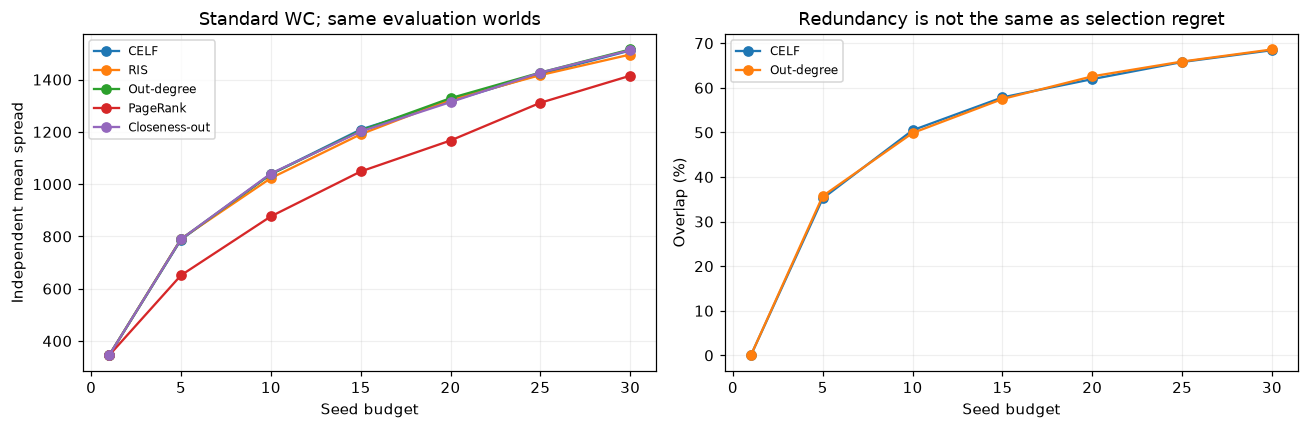

In [22]:
sample_indices=np.random.default_rng(SEED).choice(N,400,replace=False)
correlation_rows=[]
for col in cols:
    rho=stats.spearmanr(metrics.loc[[node_ids[i] for i in sample_indices],col],singleton_train[sample_indices]).statistic
    correlation_rows.append({'centrality':col,'spearman_vs_simulated_singleton_spread':rho,'sample_nodes':400,'selection_worlds':MC_TRAIN})
spread_correlations=pd.DataFrame(correlation_rows).sort_values('spearman_vs_simulated_singleton_spread',ascending=False)
display(save_table(spread_correlations,'centrality_vs_spread'))
single_nodes=sorted(set(im_indices)|set(im_methods['Out-degree']))
single_scores=evaluate_plans({str(i):[i] for i in single_nodes},P_standard,MC_TEST,TEST_WORLD_SEED,[1])
redundancy_rows=[]
for method in ['CELF','Out-degree']:
    for j,k in enumerate(K_VALUES):
        individual=sum(single_scores[str(i)][:,0] for i in im_methods[method][:k])
        joint=im_scores[method][:,j]
        assert np.all(individual>=joint)
        redundancy_rows.append({'method':method,'k':k,'sum_individual_spread':individual.mean(),
            'joint_spread':joint.mean(),'overlap_fraction':1-joint.mean()/individual.mean()})
redundancy=pd.DataFrame(redundancy_rows);display(save_table(redundancy,'set_redundancy'))
fig,ax=plt.subplots(1,2,figsize=(12,4))
for method in ['CELF','RIS','Out-degree','PageRank','Closeness-out']:
    d=im_results[im_results.method==method];ax[0].plot(d.k,d.spread,'o-',label=method)
for method,d in redundancy.groupby('method'):ax[1].plot(d.k,100*d.overlap_fraction,'o-',label=method)
ax[0].set(xlabel='Seed budget',ylabel='Independent mean spread',title='Standard WC; same evaluation worlds')
ax[1].set(xlabel='Seed budget',ylabel='Overlap (%)',title='Redundancy is not the same as selection regret')
for a in ax:a.legend(fontsize=8);a.grid(alpha=.2)
save_figure('06_influence_and_redundancy')


## 23. Readable network figures and standalone interactive artifacts

**Purpose and why:** Existing network figures contain overlapping labels, and some HTML resources reference absent local dependencies. New visualizations should state exactly which subgraph is displayed.

**What the next cell does:** Draw a deterministic high-degree core augmented with the twenty training-selected sensors. Number sensors and provide a lookup table. Build a self-contained Plotly network explorer and dashboard with JavaScript embedded.

**How to read the output:** The core is a visualization filter only. Selection and evaluation used their full declared graphs. Static overview hides directed arrows for readability; the interactive hover identifies nodes, and the caption states that edges are displayed without arrowheads.


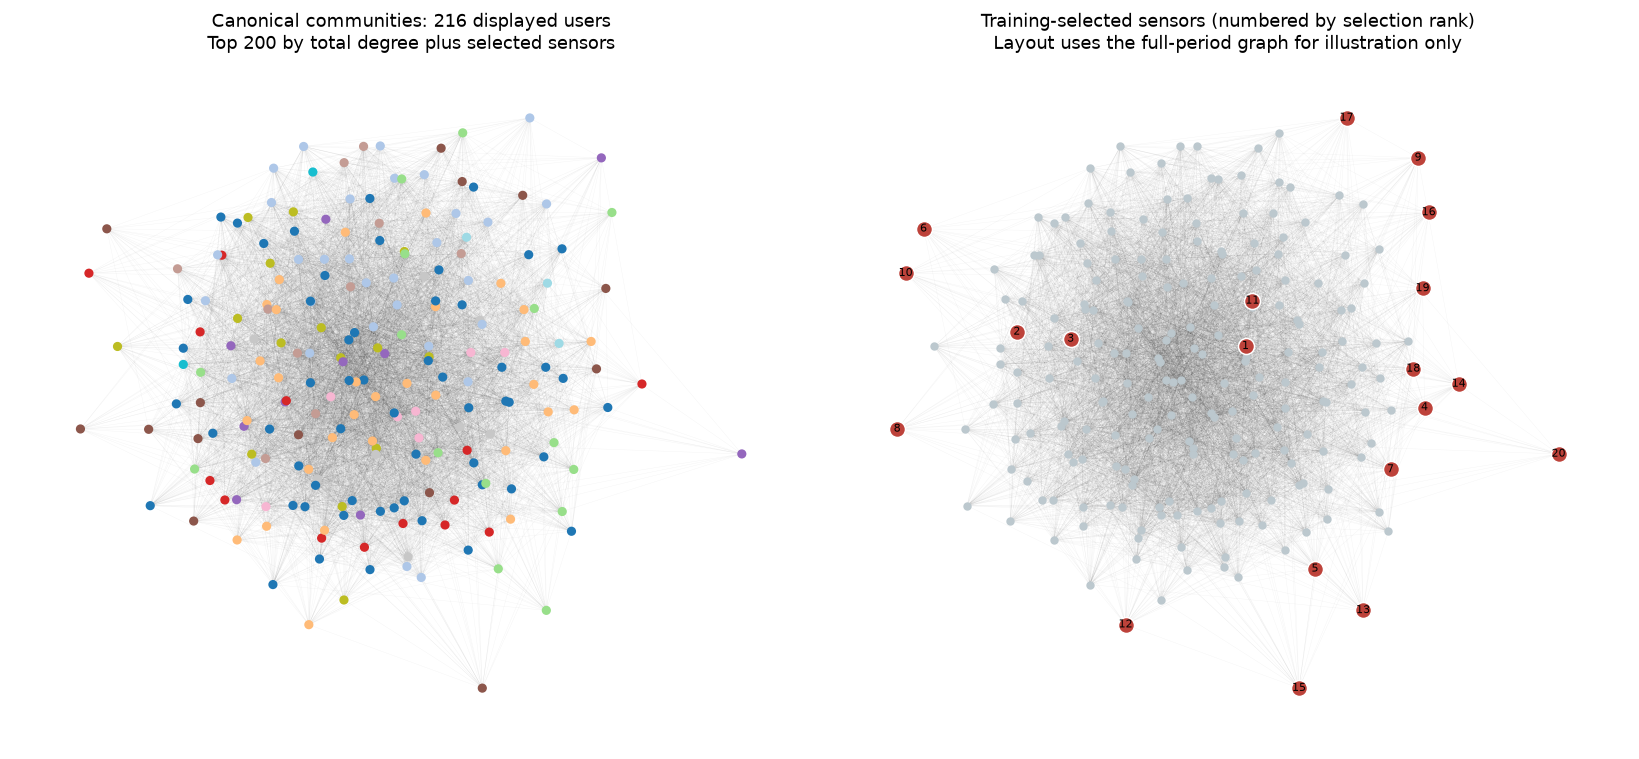

Saved self-contained network_explorer.html and results_dashboard.html (zoom/hover; fixed node positions).


In [23]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
S=set(detector[:K_REPORT]);core_users=ranked(metrics.total_degree.to_dict(),node_ids,200)
shown=sorted(set(core_users)|S);sub=U.subgraph(shown).copy()
pos=nx.spring_layout(sub,seed=SEED,iterations=70,weight='weight')
sensor_rank={u:i+1 for i,u in enumerate(detector[:K_REPORT])}
fig,ax=plt.subplots(1,2,figsize=(15,7))
for a in ax:
    nx.draw_networkx_edges(sub,pos,ax=a,width=.3,alpha=.045);a.axis('off')
nx.draw_networkx_nodes(sub,pos,ax=ax[0],node_size=25,node_color=[community[u] for u in sub],cmap=plt.cm.tab20)
ax[0].set_title(f'Canonical communities: {len(sub)} displayed users\nTop 200 by total degree plus selected sensors')
other=[u for u in sub if u not in S]
nx.draw_networkx_nodes(sub,pos,ax=ax[1],nodelist=other,node_size=20,node_color='#bcc8ce')
nx.draw_networkx_nodes(sub,pos,ax=ax[1],nodelist=sorted(S),node_size=110,node_color='#bd423a',edgecolors='white')
nx.draw_networkx_labels(sub,pos,ax=ax[1],labels={u:str(sensor_rank[u]) for u in S},font_size=7,font_color='black')
ax[1].set_title('Training-selected sensors (numbered by selection rank)\nLayout uses the full-period graph for illustration only')
save_figure('07_core_and_sensors')
save_table(pd.DataFrame([{'rank':sensor_rank[u],'Id':u,'Label':labels[u],'canonical_community':community[u]} for u in detector[:K_REPORT]]),'sensor_figure_key')
ex=[];ey=[]
for u,v in sub.edges():ex.extend([pos[u][0],pos[v][0],None]);ey.extend([pos[u][1],pos[v][1],None])
network_fig=go.Figure(go.Scatter(x=ex,y=ey,mode='lines',line={'width':.4,'color':'#c7d0d5'},hoverinfo='skip',showlegend=False))
network_fig.add_trace(go.Scatter(x=[pos[u][0] for u in shown],y=[pos[u][1] for u in shown],mode='markers',
    marker={'size':[15 if u in S else 7 for u in shown],'color':['#bd423a' if u in S else '#42889f' for u in shown]},
    text=[f'{labels[u]} | degree {G.degree(u)} | community {community[u]} | sensor rank {sensor_rank.get(u,"—")}' for u in shown],
    hovertemplate='%{text}<extra></extra>',showlegend=False))
network_fig.update_layout(title=f'Observed HN core and training-selected sensors ({len(shown)} users; undirected display)',
    height=750,xaxis={'visible':False},yaxis={'visible':False},template='plotly_white')
network_fig.write_html(OUT/'network_explorer.html',include_plotlyjs=True,full_html=True)
dashboard=make_subplots(rows=1,cols=2,subplot_titles=('Held-out detection','Independent simulated spread'))
for method in ['CELF-detect','Top-reach','Out-degree','PageRank']:
    d=test_results[test_results.method==method];dashboard.add_trace(go.Scatter(x=d.k,y=100*d.detection_rate,name=method,mode='lines+markers'),1,1)
for method in ['CELF','RIS','Out-degree','PageRank']:
    d=im_results[im_results.method==method];dashboard.add_trace(go.Scatter(x=d.k,y=d.spread,name='IM: '+method,mode='lines+markers'),1,2)
dashboard.update_xaxes(title_text='Budget k');dashboard.update_yaxes(title_text='Outbreaks detected (%)',row=1,col=1)
dashboard.update_yaxes(title_text='Expected active nodes',row=1,col=2)
dashboard.update_layout(height=550,title='Completion results: held-out detection and model-based influence',template='plotly_white')
dashboard.write_html(OUT/'results_dashboard.html',include_plotlyjs=True,full_html=True)
print('Saved self-contained network_explorer.html and results_dashboard.html (zoom/hover; fixed node positions).')


## 24. Reconcile prior claims and document what cannot be recovered

**Purpose and why:** A complete case study must distinguish tested results, corrected interpretations and evidence that is genuinely unavailable.

**What the next cell does:** Create a claims register and a remaining-evidence register. Record the old production parameters, column-name mismatch, sensitivity outcome and missing provenance artifacts without changing historical files.

**How to read the output:** “Completed” below means the analytical correction exists in this notebook. Missing raw collection evidence remains an external dependency; existing permalinks alone are not proof of historical API collection.


In [24]:
old_exp=json.loads((ROOT/'experiment_summary.json').read_text())
claims=[
 ('52.1% detection with 20 sensors','Reproduced, in-sample only','Use the new temporal test table for out-of-period performance.'),
 ('Greedy 597 / CELF 260 evaluations','Earlier run, not the saved production run',f'Saved production: {old_exp["greedy_vs_celf"]["greedy_evals"]} / {old_exp["greedy_vs_celf"]["celf_evals"]}; k=5, 500 worlds, pool=2000.'),
 ('All reported metrics are Python-computed','Mixed provenance','Saved gephi_node_metrics.csv has Gephi internal names; canonical metrics are newly computed and labelled.'),
 ('10 communities in every analysis','Mixed partitions','Report canonical partition/Q together; retain saved Gephi partition separately.'),
 ('PageRank is worst predictor','Contradicted by the old correlation CSV','Old eigenvector rho=0.655 is lower than PageRank rho=0.668; use the new full comparison table.'),
 ('WC is exactly 1/in-degree in old code','Old code caps p at 0.5','New primary experiment uses uncapped WC; capped WC is explicit sensitivity.'),
 ('RIS and CELF used the same scoring worlds','Not in the old merged results','New comparison uses common independent worlds and paired Monte Carlo intervals.'),
 ('Fixed theta RIS inherits a certified guarantee','Not established','20,000 RR sets are an experimental budget; no epsilon/delta certification is claimed.'),
 ('CELF-detect reward is monotone as written','Old reward could be negative','New reward clips at zero; toy and real-data tests included.'),
 ('Large degree redundancy proves a large CELF gain','Does not follow','Compare actual joint spread and paired differences; both sets may be redundant.'),
 ('Model sensitivity is stable','Saved alternate CELF run has 0/10 overlap','Report the sensitivity failure and new RIS-based model comparisons.'),
 ('13 months of elapsed observations','13 calendar months touched','Elapsed time is about one year; exact timestamps in dataset_audit.csv.'),
 ('Usernames exist only in the private mapping','Incorrect for existing files','Primary CSV and historical detection exports also contain usernames; new outputs use pseudonyms.'),
 ('Mean shortest path 2.542 is a directed result','Earlier code uses the undirected projection','Label graph direction for every distance statistic.'),
 ('Log-log slope establishes scale-free structure','Insufficient evidence','Use empirical distribution/CCDF; no formal power-law conclusion.'),
 ('Half-activity means peak activity','Different quantities','Half-activity uses the median retained reply timestamp; peak is not estimated.'),
 ('Closeness was approximated for every node','Old local code evaluated only 600 nodes','New closeness is exact for all nodes with explicit direction.'),
 ('Sparse/disconnected graphs make IM undefined','Mathematically incorrect','IM remains defined, but practical spread and experiment informativeness can be limited.'),
 ('A timestamped study is impossible on any benchmark','Overbroad','The cited static benchmarks lack the necessary event timing; other timestamped datasets may support detection.'),
 ('All six heuristic baselines were used in original IM','Closeness was absent from the main comparison','New comparison explicitly includes outward closeness.'),
 ('Re-run old main notebook against current metrics unchanged','Exact-name checks skip some Gephi columns','This notebook recomputes and names its centralities consistently.'),
 ('Cascade GIF represents primary experiment probabilities','Illustrative only','Old animation doubles probabilities on a filtered subgraph; it is not a validation result.')]
claims_df=pd.DataFrame(claims,columns=['prior_claim_or_issue','finding','resolution'])
save_table(claims_df,'claims_reconciliation')
remaining=pd.DataFrame([
 {'item':'Original collection and cleaning scripts, raw API responses and audit logs','status':'Not present in supplied project','needed_for':'Recollection and independent verification of acquisition/cleaning counts'},
 {'item':'Earlier Reddit/GitHub attempts and HN v1/v2 datasets','status':'Narrative only in supplied project','needed_for':'Verification of platform rejection and earlier-version statistics'},
 {'item':'Prospective monitoring data / unbiased sampling frame','status':'New data required','needed_for':'Future operational validation and removal of original population-selection bias'},
 {'item':'Ground-truth adoption or causal influence labels','status':'Not observed','needed_for':'Claims about adoption/causality rather than reply attention'},
 {'item':'Faculty rubric, final formatting requirements and author details','status':'Not supplied','needed_for':'Final submission formatting and rubric compliance'},
 {'item':'Browser interaction testing of generated HTML','status':'Not claimed by notebook','needed_for':'Visual/interaction QA in the presentation browser'}])
display(save_table(remaining,'remaining_evidence_requirements'))
print(f'{len(claims_df)} claims/issues reconciled. Historical files preserved.')


,item,status,needed_for
0,"Original collection and cleaning scripts, raw ...",Not present in supplied project,Recollection and independent verification of a...
1,Earlier Reddit/GitHub attempts and HN v1/v2 da...,Narrative only in supplied project,Verification of platform rejection and earlier...
2,Prospective monitoring data / unbiased samplin...,New data required,Future operational validation and removal of o...
3,Ground-truth adoption or causal influence labels,Not observed,Claims about adoption/causality rather than re...
4,"Faculty rubric, final formatting requirements ...",Not supplied,Final submission formatting and rubric compliance
5,Browser interaction testing of generated HTML,Not claimed by notebook,Visual/interaction QA in the presentation browser


22 claims/issues reconciled. Historical files preserved.


## 25. Generate a report from the actual new results

**Purpose and why:** The earlier draft contains placeholders and stale hardcoded numbers. Report text should be generated from the results actually computed here.

**What the next cell does:** Write a standalone completion report, figure captions and an output guide. Clearly separate the historical replication, held-out detector and model-based influence experiments.

**How to read the output:** The report is a research completion addendum, not a promise of a perfect or deployment-ready system. Its limitations and confidence intervals are part of the result.


In [25]:
test20=test_results[(test_results.method=='CELF-detect')&(test_results.k==K_REPORT)].iloc[0]
top20=test_results[(test_results.method=='Top-reach')&(test_results.k==K_REPORT)].iloc[0]
rand20=random_results[random_results.k==K_REPORT].detection_rate.mean()
im30=im_results[(im_results.k==30)&~im_results.method.str.startswith('Random-')]
cel30=float(im30.loc[im30.method=='CELF','spread'].iloc[0]);ris30=float(im30.loc[im30.method=='RIS','spread'].iloc[0])
degree30=float(im30.loc[im30.method=='Out-degree','spread'].iloc[0])
report=f'''# Completion report: HN influence maximization and early detection

## Research question
Which small set of users should be monitored to detect significant observed discussions early?
The application is sensor allocation; classical influence maximization provides a separate model-based comparison.

## Data and integrity
The supplied dataset contains {len(raw):,} retained reply interactions, {N:,} users,
{G.number_of_edges():,} weighted directed edges and {len(events):,} observed discussions.
The observation period is {raw.ts.min()} to {raw.ts.max()}: approximately one year spanning 13 calendar months.
All row-level identity, uniqueness and aggregation checks passed. This proves internal consistency,
not external acquisition provenance. Collection scripts and raw API responses were not supplied.
All new user-level outputs use pseudonyms; the original source files do contain raw usernames.

## Network definitions
Edges point from parent author to replier. Out-degree counts distinct observed repliers to an author's comments;
in-degree counts distinct parent authors the user replied to. Undirected weights explicitly sum reciprocal counts.
Canonical weighted Louvain found {len(communities)} communities, with modularity Q={Q:.4f}.
Closeness is exact and direction-labelled; betweenness uses 300 sampled sources. A degree CCDF is reported
without asserting a fitted power law. See network_structure.csv and canonical_node_metrics.csv.

## Historical result reproduced
The old 20-sensor set detects {reproduced['detection_rate']:.1%} of 3,418 outbreaks in the full supplied sample,
with median delay {reproduced['median_delay_h']:.2f}h and precision {reproduced['precision']:.3f}.
These are in-sample results and must not be described as a held-out or prospective evaluation.

## Corrected temporal evaluation
Whole observed discussions are split chronologically at {protocol['cut1_utc']} and {protocol['cut2_utc']}.
{len(purged)} boundary-crossing discussions are purged. Candidates, graph baselines and the {H:.2f}h
horizon are derived only from training. The nonnegative early reward is max(0,1-delay/H), averaged across outbreaks.
CELF and greedy select identical first five sensors on the training objective. The primary budget is the
pre-specified k=20; a secondary validation-only rule selects k={K_VALIDATED}.

{split_table.to_markdown(index=False)}

At k=20 on the test split, CELF detects {test20.detection_rate:.1%}, compared with Top-reach at
{top20.detection_rate:.1%} and a mean of {rand20:.1%} across 100 random selections.
Detection within the training horizon is {test20.detection_within_horizon:.1%}; precision is
{test20.precision:.3f}; median delay among detected outbreaks is {test20.median_delay_detected_h:.2f}h.
The miss-adjusted mean capped delay is {test20.mean_capped_delay_h:.2f}h.
Rates refer only to retained observed discussion data, not every HN discussion.
The relative results must be reported even when they do not favor CELF: training-objective optimization
does not guarantee superior future detection. This experiment tests that assumption rather than presuming it.

{test_results[test_results.k==20][['method','detection_rate','detection_within_horizon','precision','mean_reward']].round(4).to_markdown(index=False)}

### Generalization across time
Normalized early reward at the same frozen 20-sensor budget:

{generalization.pivot(index='method',columns='split',values='mean_reward').round(4).to_markdown()}

Differences across these periods may reflect estimation error, changing user participation, discussion
composition and the original sampling design. This descriptive comparison does not identify a causal explanation
and was not used to tune the test model.

### Uncertainty and interpretation
Paired CELF-minus-Top-reach differences and exploratory intervals:

{intervals.round(4).to_markdown(index=False)}

Story resampling may understate dependence; calendar-week resampling has only {len(blocks)} blocks.
Delay comparisons on commonly detected outbreaks are in common_detected_delay_comparison.csv.
Sensitivity checks use validation only. No test result is used to retune the frozen sensor selection.
The alert ledger is an offline replay with eventual size labels, not a live prediction system.

## Influence maximization
Primary propagation is standard, uncapped Weighted Cascade: p(u,v)=1/in-degree(v).
CELF uses all {N:,} candidates and {MC_TRAIN} fixed selection worlds. Greedy and CELF select
identical first five seeds. RIS uses {THETA:,} RR sets. All seed sets are evaluated on the same
{MC_TEST} independent live-edge worlds. At k=30, mean spread is CELF={cel30:.2f}, RIS={ris30:.2f},
and out-degree={degree30:.2f}. The paired Monte Carlo interval must accompany small differences.
CELF is not guaranteed to beat a structural baseline on independent worlds after optimizing a finite sample.
Computational timing separates reusable preprocessing from selection; evaluation is separate.

{im30[['method','spread','mc_lower95','mc_upper95']].round(3).to_markdown(index=False)}

The classical greedy guarantee concerns the stated monotone submodular objective; here the directly optimized
objective is a finite-world estimate. A fixed 20,000-RR-set implementation is not claimed to have a calibrated
epsilon/delta guarantee. Probability-model sensitivity is reported separately in probability_sensitivity.csv.
The earlier alternate CELF run recorded 0/10 seed overlap; probability robustness must not be claimed.
Set redundancy is measured directly for CELF and degree; redundancy alone does not establish a large
advantage over a competing set. Centrality correlations are against simulated reach, not observed adoption.

## Completed artifacts
Seven PNG figure groups, two self-contained interactive HTML files, canonical graph metrics,
training sensor rankings, a held-out alert ledger, comparison tables, uncertainty tables, sensitivity tables,
claims reconciliation and a SHA-256 provenance manifest are provided in this folder.

## Remaining limitations
{remaining.to_markdown(index=False)}

The full-period activity-filtered sampling frame is already baked into the supplied data. A chronological split
cannot remove that selection bias. Story starts are first retained replies; true starts and complete cascades
are unavailable. Purging can bias duration composition, and test-end censoring can affect eventual sizes.
Replies do not establish adoption, agreement or causality. Arrival-position differences are descriptive,
not statistical proof that an algorithm identified causal influencers. No live deployment or perfect future
accuracy is claimed.

## Primary methodological references
- Kempe, Kleinberg and Tardos (2003), [Maximizing the Spread of Influence through a Social Network](https://www.cs.cornell.edu/home/kleinber/kdd03-inf.pdf).
- Leskovec et al. (2007), [Cost-effective Outbreak Detection in Networks](https://www.cs.cmu.edu/~guestrin/Publications/KDD2007/kdd2007.pdf).
- Borgs et al. (2014), [Maximizing Social Influence in Nearly Optimal Time](https://www.microsoft.com/en-us/research/publication/maximizing-social-influence-nearly-optimal-time/).
- Li, Fan, Wang and Tan (2018), Influence Maximization on Social Graphs: A Survey, IEEE TKDE 30(10), 1852–1872: the original project's theoretical framing, not the source of this dataset.
'''
(OUT/'COMPLETION_REPORT.md').write_text(report)
captions={
 '01_structure.png':'Observed total-degree distribution, empirical CCDF and canonical summed-weight Louvain community sizes. No formal power-law fit is claimed.',
 '02_centrality_correlations.png':'Spearman correlations of consistently defined measures on the full graph. Betweenness is sampled; inward and outward closeness are exact.',
 '03_heldout_detection.png':'Test detection, precision and miss-adjusted delay for training-selected sensors. Random shading is the 2.5–97.5 percentile across sensor draws, not a future-performance confidence interval.',
 '04_paired_uncertainty.png':'Paired CELF-minus-Top-reach differences at 20 sensors with exploratory story and week-block bootstrap intervals.',
 '05_validation_sensitivity.png':'Sensitivity to participant threshold and training horizon; all displayed outcomes use validation, not test, data.',
 '06_influence_and_redundancy.png':'Influence methods evaluated on common independent standard-WC worlds, alongside measured overlap within selected sets.',
 '07_core_and_sensors.png':'Top 200 total-degree users plus the 20 training-selected sensors; undirected display only. Full-period layout is illustrative and was not used for sensor selection. Sensor numbers map to sensor_figure_key.csv.'}
(OUT/'FIGURE_CAPTIONS.md').write_text('# Figure captions\n\n'+'\n\n'.join(f'**{name}** — {text}' for name,text in captions.items()))
(OUT/'README.md').write_text('''# Completion outputs
Start with COMPLETION_REPORT.md and the executed ../PROJECT_COMPLETION.ipynb.

- dataset_audit / network_structure / canonical_node_metrics: data and graph definitions.
- chronological_splits / detection_protocol / training_sensor_rankings: frozen detection protocol.
- test_detection_results / random_detection_replicates / paired_detection_intervals: held-out evidence.
- test_alert_ledger: offline, pseudonym-only alerts with retrospective labels.
- independent_influence_results / paired_influence_intervals: common-world influence comparisons.
- probability_sensitivity / ris_sampling_sensitivity / validation_sensitivity: robustness checks.
- claims_reconciliation: explanations of discrepancies in historical reports and code.
- remaining_evidence_requirements: unavailable evidence and external work, explicitly retained.
- input_manifest.json / run_manifest.json: input hashes, parameters and checks.
- FIGURE_CAPTIONS.md: captions for all seven generated figure groups.
- network_explorer.html / results_dashboard.html: standalone embedded-JavaScript views; open locally in a browser.

No original project artifacts are replaced. Re-running the notebook refreshes only this folder.
Do not treat the offline alert ledger as a live monitoring service or simulated spread as proven adoption.
''')
display(Markdown(f'**Report generated:** `completion_outputs/COMPLETION_REPORT.md`\n\nHeld-out k=20 detection: **{test20.detection_rate:.1%}**; precision: **{test20.precision:.3f}**.'))


**Report generated:** `completion_outputs/COMPLETION_REPORT.md`

Held-out k=20 detection: **26.8%**; precision: **0.866**.

## 26. Final integrity and completeness checks

**Purpose and why:** A finished executed notebook should leave a machine-readable record of what passed and prove it preserved the original work.

**What the next cell does:** Validate result bounds, seed uniqueness, source-file hashes, artifact existence and self-contained HTML references. Save manifests with settings and checks.

**How to read the output:** Passing confirms this run’s internal checks. It does not certify external data provenance, theoretical sample complexity, browser rendering or future operational performance.


In [26]:
assert all(len(S)==len(set(S))==K_MAX for S in sensor_methods.values())
assert all(len(S)==len(set(S))==K_MAX for S in im_methods.values())
assert test_results.detection_rate.between(0,1).all()
assert test_results.mean_reward.between(0,1).all()
assert test_results.detection_within_horizon.le(test_results.detection_rate+1e-12).all()
assert np.isfinite(im_results.spread).all() and im_results.spread.between(1,N).all()
assert all(np.all(np.diff(v,axis=1)>=0) for v in im_scores.values())
assert all(sha256(ROOT/name)==value for name,value in original_hashes.items()), 'An original file changed during the run.'
assert not any(marker in report for marker in ['[FILL','[MISSING'])
import re
for name in ['network_explorer.html','results_dashboard.html']:
    html=(OUT/name).read_text()
    assert not re.search(r'<script[^>]+src=',html,re.I), 'External JS reference found.'
    assert 'Plotly.newPlot' in html
for name in captions:assert (OUT/name).stat().st_size>1000
checks=['row/edge consistency','historical metrics reproduced','split disjointness and chronology',
        'closeness orientation','coverage monotonicity/submodularity toy checks','CELF equals Greedy on training coverage',
        'CELF equals Greedy on fixed influence worlds','independent evaluation seed','valid result bounds',
        'unique selections','standalone HTML source checks','no report placeholders','all original file hashes unchanged']
(OUT/'input_manifest.json').write_text(json.dumps(original_hashes,indent=2))
manifest={'versions':versions,'seed':SEED,'mc_train':MC_TRAIN,'mc_test':MC_TEST,'rr_sets':THETA,
          'train_world_seed':TRAIN_WORLD_SEED,'test_world_seed':TEST_WORLD_SEED,
          'random_detection_repeats':RANDOM_REPEATS,'bootstrap_replicates':BOOTSTRAPS,
          'protocol':protocol,'checks_passed':checks,'original_files_unchanged':len(original_hashes),
          'outputs':[p.name for p in sorted(OUT.iterdir()) if p.is_file()]}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
display(pd.DataFrame({'check':checks,'status':'PASS'}))
print(f'COMPLETE: {len(checks)} checks passed; {len(original_hashes)} original files unchanged.')
print('Read COMPLETION_REPORT.md for results and remaining evidence requirements.')


,check,status
0,row/edge consistency,PASS
1,historical metrics reproduced,PASS
2,split disjointness and chronology,PASS
3,closeness orientation,PASS
4,coverage monotonicity/submodularity toy checks,PASS
5,CELF equals Greedy on training coverage,PASS
6,CELF equals Greedy on fixed influence worlds,PASS
7,independent evaluation seed,PASS
8,valid result bounds,PASS
9,unique selections,PASS


COMPLETE: 13 checks passed; 77 original files unchanged.
Read COMPLETION_REPORT.md for results and remaining evidence requirements.


## What to use for the case study now

Use the new report and tables together: historical in-sample numbers must retain their label, and new test
numbers must retain their chronological protocol and uncertainty. Cite the specific graph/probability definitions
used for every figure. Review `remaining_evidence_requirements.csv` before claiming collection reproducibility,
causal validation or live operational readiness. The completed analysis does not manufacture missing evidence.
